In [41]:
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category

In [ ]:
import os
import numpy as np
from das2 import get_source
import das2
import matplotlib.pyplot as plt


# ──────────────────────────────────────────────────────────────────────────────
# GLOBAL CONFIG
# ──────────────────────────────────────────────────────────────────────────────
WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

LFRH_YLIM   = (2e4, 2e5)
LHRL_YLIM   = (5e1, 2e4)
B_YLIM      = (5e1, 2e4)

LFRH_LOGNORM = (1e-14, 1e-11)
LHRL_LOGNORM = (1e-14, 1e-8)
B_LOGNORM    = (1e-9, 1e-4)

OVERLAY_LW    = 1.0
OVERLAY_ALPHA = 0.9
PLOT_FCE_FZ_FUHR = True


# ──────────────────────────────────────────────────────────────────────────────
# WAVES MAIN
# ──────────────────────────────────────────────────────────────────────────────
def make_waves_segment(
    start_time,
    end_time,
    server_url=SERVER_URL_WAVES,
    label="segment",
    outdir=WAVES_FIG_OUTDIR,
    save_fig=True,
    show_fig=True,
    overlay_lw=OVERLAY_LW,
    overlay_alpha=OVERLAY_ALPHA,
    plot_fce_fz_fuhr=PLOT_FCE_FZ_FUHR,
    lfrh_ylim=LFRH_YLIM,
    lhrl_ylim=LHRL_YLIM,
    lfrh_lognorm=LFRH_LOGNORM,
    lhrl_lognorm=LHRL_LOGNORM,
    plot_b_panel=True,
    b_ylim=B_YLIM,
    b_lognorm=B_LOGNORM,
):
    import numpy as np
    import pandas as pd
    import matplotlib.dates as mdates
    import matplotlib.patheffects as pe
    from matplotlib.colors import LogNorm
    from matplotlib.gridspec import GridSpec
    from matplotlib.ticker import FixedLocator

    # Fetch WAVES
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time)})
    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")
    whis, middle = ds[0], ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

        spec = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2:
            raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
        if spec.shape[1] != freqs.size:
            spec = spec.T

        return (
            np.array(times, dtype='datetime64[ms]'),
            np.asarray(freqs, float),
            np.asarray(spec, float),
        )

    times_lhrl, freqs_lhrl, spec_lhrl = extract_arrays(whis)
    times_lfrh, freqs_lfrh, spec_lfrh = extract_arrays(middle)

    def sanitize_linear(a):
        a = np.asarray(a, float).copy()
        a[~np.isfinite(a)] = np.nan
        a[a <= 0] = np.nan
        return a

    spec_lhrl_plot = sanitize_linear(spec_lhrl)
    spec_lfrh_plot = sanitize_linear(spec_lfrh)

    # MAG (b=True)
    times_b = freqs_b = spec_b = None
    spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time), 'b': True})
            if len(ds_b) < 1:
                print("No magnetic dataset returned for b=True; skipping B panel.")
                plot_b_panel = False
            else:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = sanitize_linear(spec_b)
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset (b=True): {e}")
            plot_b_panel = False

    # Use LHRL cadence/time for ephemeris sampling
    eph_times = times_lhrl
    t0 = eph_times[0]
    t_sec = (eph_times - t0) / np.timedelta64(1, "s")
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dtcad) or dtcad <= 0:
        dtcad = 1.0

    # ──────────────────────────────────────────────────────────
    # FIGURE LAYOUT
    # ──────────────────────────────────────────────────────────
    nrows = 3 if plot_b_panel else 2
    fig_h = 9 if plot_b_panel else 7

    fig = plt.figure(figsize=(10, fig_h), dpi=200)
    gs = GridSpec(
        nrows, 2, figure=fig,
        width_ratios=[1, 0.03],
        height_ratios=[1] * nrows,
        wspace=0.02, hspace=0.00
    )

    ax_lfrh = fig.add_subplot(gs[0, 0])
    ax_lhrl = fig.add_subplot(gs[1, 0], sharex=ax_lfrh)
    cax_lfrh = fig.add_subplot(gs[0, 1])
    cax_lhrl = fig.add_subplot(gs[1, 1])

    if plot_b_panel:
        ax_bsp = fig.add_subplot(gs[2, 0], sharex=ax_lfrh)
        cax_b  = fig.add_subplot(gs[2, 1])
        bottom_ax = ax_bsp
    else:
        ax_bsp = None
        cax_b = None
        bottom_ax = ax_lhrl

    def shrink_cax(cax, frac=0.90):
        pos = cax.get_position()
        new_h = pos.height * frac
        new_y = pos.y0 + (pos.height - new_h) / 2
        cax.set_position([pos.x0, new_y, pos.width, new_h])

    # LFRH spectrogram
    vmin_mid, vmax_mid = lfrh_lognorm
    im_lfrh = ax_lfrh.pcolormesh(
        times_lfrh, freqs_lfrh, spec_lfrh_plot.T,
        norm=LogNorm(vmin=vmin_mid, vmax=vmax_mid),
        cmap="turbo", shading="nearest"
    )
    ax_lfrh.set_ylim(*lfrh_ylim)
    ax_lfrh.set_yscale("log")
    ax_lfrh.set_facecolor("black")
    ax_lfrh.set_ylabel("Frequency (Hz)")
    ax_lfrh.tick_params(labelbottom=False)

    cb = fig.colorbar(im_lfrh, cax=cax_lfrh)
    cb.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb.ax.tick_params(labelsize=8)
    shrink_cax(cax_lfrh, 0.90)

    # LHRL spectrogram
    vmin_wh, vmax_wh = lhrl_lognorm
    im_lhrl = ax_lhrl.pcolormesh(
        times_lhrl, freqs_lhrl, spec_lhrl_plot.T,
        norm=LogNorm(vmin=vmin_wh, vmax=vmax_wh),
        cmap="turbo", shading="nearest"
    )
    ax_lhrl.set_ylim(*lhrl_ylim)
    ax_lhrl.set_yscale("log")
    ax_lhrl.set_facecolor("black")
    ax_lhrl.set_ylabel("Frequency (Hz)")
    ax_lhrl.tick_params(labelbottom=False)

    cb2 = fig.colorbar(im_lhrl, cax=cax_lhrl)
    cb2.set_label(r'ESD [V$^2$ m$^{-2}$ Hz$^{-1}$]')
    cb2.ax.tick_params(labelsize=8)
    shrink_cax(cax_lhrl, 0.90)

    # MAG panel
    if plot_b_panel and (spec_b_plot is not None):
        vmin_b, vmax_b = b_lognorm
        im_b = ax_bsp.pcolormesh(
            times_b, freqs_b, spec_b_plot.T,
            norm=LogNorm(vmin=vmin_b, vmax=vmax_b),
            cmap="turbo", shading="nearest"
        )
        ax_bsp.set_ylim(*b_ylim)
        ax_bsp.set_yscale("log")
        ax_bsp.set_facecolor("black")
        ax_bsp.set_ylabel("Frequency (Hz)")

        cb3 = fig.colorbar(im_b, cax=cax_b)
        cb3.set_label(r'PSD [nT$^2$ Hz$^{-1}$]')
        cb3.ax.tick_params(labelsize=8)
        shrink_cax(cax_b, 0.90)
    elif plot_b_panel:
        ax_bsp.axis("off")
        cax_b.axis("off")

    for ax in [ax_lfrh, ax_lhrl]:
        ax.tick_params(axis="x", which="both", bottom=False, top=False,
                       labelbottom=False, labeltop=False)

    # Title
    ax_lfrh.set_title(
        f"Juno Waves Spectrogram {pd.to_datetime(start_time).strftime('%Y-%m-%d')} | {label}\n"
        r"Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]"
    )

    # ──────────────────────────────────────────────────────────
    # Overlays f_pe (+ optional f_ce)
    # ──────────────────────────────────────────────────────────
    axes_for_overlays = [ax_lfrh, ax_lhrl]
    if plot_b_panel and ax_bsp is not None and ax_bsp.axison:
        axes_for_overlays.append(ax_bsp)


    if plot_fce_fz_fuhr:
        efc_source = das2.get_source(SERVER_URL_EFC)
        ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
        efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
        efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")

        mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
        for ax_ov in axes_for_overlays:
            ax_ov.plot(
                efc_time[mask_fce], efc_freq[mask_fce],
                color="red", linewidth=overlay_lw, alpha=overlay_alpha,
                path_effects=[
                    pe.Stroke(linewidth=overlay_lw + 0.5, foreground="white", alpha=overlay_alpha),
                    pe.Normal()
                ],
                label=r"$f_{ce}$ (FGM)" if ax_ov is ax_lhrl else None
            )

    ax_lhrl.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    # ──────────────────────────────────────────────────────────
    # Bottom x-axis formatting
    # ──────────────────────────────────────────────────────────
    total_hours = (eph_times[-1] - eph_times[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2

    major = mdates.HourLocator(interval=tick_interval_h)
    minor = mdates.MinuteLocator(interval=10)
    fmt   = mdates.DateFormatter("%H:%M")

    bottom_ax.xaxis.set_major_locator(major)
    bottom_ax.xaxis.set_minor_locator(minor)
    bottom_ax.xaxis.set_major_formatter(fmt)
    bottom_ax.set_xlabel("UTC")

    # ──────────────────────────────────────────────────────────
    # Ephemeris rows
    # ──────────────────────────────────────────────────────────
    t0h = eph_times[0].astype("datetime64[h]")
    t1h = eph_times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, "h"))
    all_ticks = np.unique(np.concatenate(([eph_times[0]], maj, [eph_times[-1]])))

    py_ticks = [t.tolist() for t in all_ticks]
    all_tick_nums = mdates.date2num(py_ticks)

    bottom_ax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    bottom_ax.xaxis.set_major_formatter(fmt)

    eph_src = get_source(SERVER_URL_EPH)
    ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]

    rad   = ds_eph["radius"]["center"].array
    lon3  = ds_eph["long"]["center"].array
    mlatE = ds_eph["mlat"]["center"].array
    mltE  = ds_eph["mlt"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    eph_time_arr = ds_eph["time"]["center"].array
    eph_time_arr = np.array(eph_time_arr, dtype="datetime64[ms]")
    if getattr(eph_time_arr, "ndim", 1) > 1:
        eph_time_arr = eph_time_arr[:, 0]

    idx_eph = [np.argmin(np.abs(eph_time_arr - mt)) for mt in all_ticks]

    row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
    row_arrays  = [rad, lon3, mlatE, mltE]
    row_spacing = 0.15

    for j, (lab, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 1)
        sax = bottom_ax.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        vals = np.asarray(arr)[idx_eph]
        sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.03)
        txt.set_ha("right")



    if save_fig:
        os.makedirs(outdir, exist_ok=True)
        safe_label = label if label else "segment"
        fname = os.path.join(outdir, f"waves_{safe_label}_{start_time}.png")
        fig.savefig(fname, dpi=300)
        print(f"Saved WAVES fig: {fname}")

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return {
        "times_lhrl": times_lhrl,
        "freqs_lhrl": freqs_lhrl,
        "spec_lhrl": spec_lhrl,
        "times_lfrh": times_lfrh,
        "freqs_lfrh": freqs_lfrh,
        "spec_lfrh": spec_lfrh,
        "times_b": times_b,
        "freqs_b": freqs_b,
        "spec_b": spec_b,
    }

import os
import numpy as np
import matplotlib.pyplot as plt


def plot_summed_frequency_bins_fft(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    period_min_min=1,
    period_max_min=15,
    outdir="WAVES_FIGS/bin_fft_plots",
    prefix="lhrl",
    save_fig=True,
    show_fig=True,
    detrend=True,
):
    """
    For a spectrogram with shape (ntime, nfreq), sum together frequency rows
    in groups of `rows_per_bin`, then for each summed band create a small
    2-panel figure:
      - top: summed line vs time
      - bottom: FFT power vs period (minutes), limited to 1-15 min

    Parameters
    ----------
    times : array-like of datetime64
        Time array of length ntime.
    freqs : array-like
        Frequency array of length nfreq.
    spec : 2D array
        Spectrogram with shape (ntime, nfreq).
    rows_per_bin : int
        Number of adjacent frequency rows to sum together.
    period_min_min : float
        Minimum period to show in minutes.
    period_max_min : float
        Maximum period to show in minutes.
    outdir : str
        Output folder.
    prefix : str
        Prefix for saved filenames.
    save_fig : bool
        Whether to save each figure.
    show_fig : bool
        Whether to display each figure.
    detrend : bool
        If True, subtract the mean before FFT.
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times)
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    # Clean data for summing
    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    # Time cadence in seconds
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid time cadence from `times`.")

    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    print(f"Number of frequency rows: {nfreq}")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} row(s) to keep bins uniform.")

    for i in range(n_bins):
        i0 = i * rows_per_bin
        i1 = i0 + rows_per_bin

        f_lo = freqs[i0]
        f_hi = freqs[i1 - 1]

        # Sum 4 rows across frequency dimension -> 1 time series
        y = np.nansum(spec_clean[:, i0:i1], axis=1)

        # FFT prep
        y_fft = y.copy()
        bad = ~np.isfinite(y_fft)
        if np.any(bad):
            y_fft[bad] = 0.0

        if detrend:
            y_fft = y_fft - np.nanmean(y_fft)

        # Real FFT
        fft_vals = np.fft.rfft(y_fft)
        fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
        power = np.abs(fft_vals) ** 2

        # Convert frequency -> period in minutes
        with np.errstate(divide="ignore", invalid="ignore"):
            period_min = 1.0 / fft_freq_hz / 60.0

        # Remove zero-frequency term and keep requested range
        mask = (
            np.isfinite(period_min)
            & (fft_freq_hz > 0)
            & (period_min >= period_min_min)
            & (period_min <= period_max_min)
        )

        period_plot = period_min[mask]
        power_plot = power[mask]

        # Sort by period ascending for plotting
        if len(period_plot) > 0:
            srt = np.argsort(period_plot)
            period_plot = period_plot[srt]
            power_plot = power_plot[srt]

        # Build figure
        fig, (ax1, ax2) = plt.subplots(
            2, 1,
            figsize=(10, 3.2),
            dpi=180,
            sharex=False,
            gridspec_kw={"height_ratios": [1, 1], "hspace": 0.15}
        )

        # Top: summed line
        ax1.plot(times, y, lw=0.9)
        ax1.set_ylabel("Summed ESD")
        ax1.set_title(f"{prefix.upper()} rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz")
        ax1.tick_params(axis="x", labelbottom=False)
        ax1.set_yscale('log')

        # Bottom: FFT power
        ax2.plot(period_plot, power_plot, lw=0.9)
        ax2.set_xlabel("Period (min)")
        ax2.set_ylabel("FFT Power")
        ax2.set_xlim(period_min_min, period_max_min)


        # Optional: mark strongest period in range
        if len(power_plot) > 0 and np.any(np.isfinite(power_plot)):
            k = np.nanargmax(power_plot)
            best_period = period_plot[k]
            ax2.axvline(best_period, ls="--", lw=0.8, color="red")
            ax2.text(
                0.98, 0.92,
                f"Peak: {best_period:.2f} min",
                transform=ax2.transAxes,
                ha="right", va="top", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
            )



        if save_fig:
            fname = os.path.join(outdir, f"{prefix}_bin_{i:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png")
            fig.savefig(fname, bbox_inches="tight")
            print(f"Saved: {fname}")

        if show_fig:
            plt.show()
        else:
            plt.close(fig)

/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_25801/2370830475.py:316: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.06, 1, 0.96])


Saved WAVES fig: WAVES_FIGS/waves_waves_only_2021-06-08T23:00:00.png


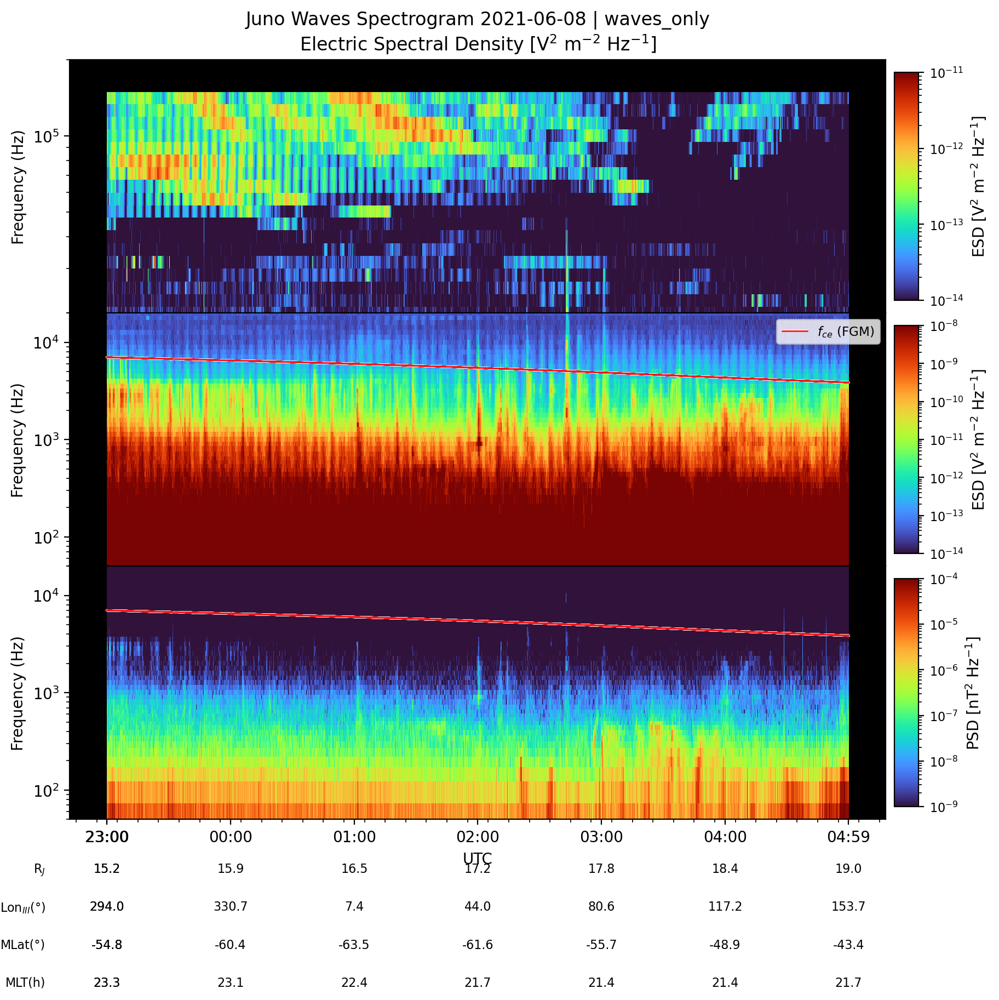

In [13]:
res = make_waves_segment(
    start_time="2021-06-08T23:00:00",
    end_time="2021-06-09T05:00:00",
    label="waves_only",
    save_fig=True,
    show_fig=True,
)

In [27]:
plot_summed_frequency_bins_fft(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    period_min_min=1,
    period_max_min=15,
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
)

Number of frequency rows: 43
Rows per bin: 4
Number of full bins: 10
Ignoring last 3 row(s) to keep bins uniform.
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_000_48.8_195.3Hz.png


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_26854/2309381904.py:512: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_001_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_002_439.4_585.9Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_003_634.8_903.3Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_004_1001.0_1416.0Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_005_1587.0_2246.0Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_006_2515.0_3540.0Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_007_3980.0_5615.0Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_008_6299.0_8936.0Hz.png
Saved: WAVES_FIGS/bin_fft_plots/lhrl_bin_009_10010.0_14160.0Hz.png


In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pywt


def plot_summed_frequency_bins_cwt_windowed(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=None,                 # if None, uses non-overlapping windows
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",       # "fractional", "mean", "zscore", "none"
    spike_threshold=1e4,               # remove absurd post-normalization spikes
    use_hann_taper=True,
    detrend_window_mean=True,
    outdir="WAVES_FIGS/bin_cwt_windowed",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
):
    """
    Sum adjacent frequency rows in groups of `rows_per_bin`, normalize each full
    summed time series, remove extreme post-normalization spikes, then run a
    time-windowed continuous wavelet transform on each frequency bin.

    Each window is analyzed separately, which makes comparison with a windowed FFT
    much fairer.
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times, dtype="datetime64[ms]")
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    # Time cadence in seconds
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid cadence from `times`.")

    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} frequency row(s).")

    # Window setup
    window_seconds = window_minutes * 60.0
    if step_minutes is None:
        step_minutes = window_minutes
    step_seconds = step_minutes * 60.0

    window_n = int(round(window_seconds / dt))
    step_n = int(round(step_seconds / dt))

    if window_n < 8:
        raise ValueError("Window too short relative to cadence.")
    if step_n < 1:
        raise ValueError("step_minutes gives step_n < 1.")

    print(f"Cadence: {dt:.2f} s")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    print(f"Window: {window_minutes} min ({window_n} samples)")
    print(f"Step: {step_minutes} min ({step_n} samples)")
    print(f"Wavelet: {wavelet_name}")
    print(f"Spike threshold after normalization: {spike_threshold:g}")

    # Target periods in minutes and seconds
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0

    # Convert requested periods -> scales
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    results = []

    def remove_extreme_spikes(y, threshold):
        """
        Replace absurd outliers |y| > threshold by linear interpolation.
        """
        y = np.asarray(y, float).copy()

        if threshold is None:
            return y, np.zeros(len(y), dtype=bool)

        bad = ~np.isfinite(y) | (np.abs(y) > threshold)

        if not np.any(bad):
            return y, bad

        good = ~bad
        x = np.arange(len(y))

        if np.sum(good) < 2:
            y[bad] = 0.0
            return y, bad

        y[bad] = np.interp(x[bad], x[good], y[good])
        return y, bad

    def normalize_series(y, mode):
        y = np.asarray(y, float)
        mean_y = np.nanmean(y)
        std_y = np.nanstd(y)

        if not np.all(np.isfinite(y)):
            y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

        if mode == "fractional":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None
            return (y - mean_y) / mean_y, "Fractional summed ESD"
        elif mode == "mean":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None
            return y / mean_y, "Normalized summed ESD"
        elif mode == "zscore":
            if not np.isfinite(std_y) or std_y == 0:
                return None, None
            return (y - mean_y) / std_y, "Standardized summed ESD"
        elif mode == "none":
            return y, "Summed ESD"
        else:
            raise ValueError("normalize_mode must be one of: 'fractional', 'mean', 'zscore', 'none'")

    for ibin in range(n_bins):
        i0 = ibin * rows_per_bin
        i1 = i0 + rows_per_bin

        f_lo = freqs[i0]
        f_hi = freqs[i1 - 1]

        # Sum selected rows over frequency dimension
        y_full = np.nansum(spec_clean[:, i0:i1], axis=1)

        y_full_norm, ylab = normalize_series(y_full, normalize_mode)
        if y_full_norm is None:
            print(f"Skipping bin {ibin}: normalization failed.")
            continue

        y_full_filt, spike_mask_full = remove_extreme_spikes(y_full_norm, spike_threshold)

        for w0 in range(0, len(times) - window_n + 1, step_n):
            w1 = w0 + window_n

            times_win = times[w0:w1]
            y_raw_win = y_full_norm[w0:w1].copy()
            y_filt_win = y_full_filt[w0:w1].copy()
            spike_mask_win = spike_mask_full[w0:w1].copy()
            n_spikes = int(np.sum(spike_mask_win))

            if len(times_win) < 8:
                continue

            # Optional detrend within each window
            y_cwt = y_filt_win.copy()
            if detrend_window_mean:
                y_cwt = y_cwt - np.nanmean(y_cwt)

            # Optional Hann taper to reduce edge artefacts
            if use_hann_taper:
                taper = np.hanning(len(y_cwt))
                y_cwt = y_cwt * taper

            # CWT for this window
            coeffs, pseudo_freq_hz = pywt.cwt(
                y_cwt, scales, wavelet_name, sampling_period=dt
            )
            power = np.abs(coeffs) ** 2
            power_plot = np.log10(power + 1e-12)

            # Strongest mean period in this window
            if power.size > 0 and np.any(np.isfinite(power)):
                mean_power_by_period = np.nanmean(power, axis=1)
                k_peak = np.nanargmax(mean_power_by_period)
                best_period = float(period_min_arr[k_peak])
            else:
                best_period = np.nan

            t0_title = np.datetime_as_string(times_win[0], unit="s").replace("T", " ")
            t1_title = np.datetime_as_string(times_win[-1], unit="s").replace("T", " ")

            fig, (ax1, ax2) = plt.subplots(
                2, 1,
                figsize=(10, 3.2),
                dpi=180,
                gridspec_kw={"height_ratios": [1, 1.6], "hspace": 0.15}
            )

            # Top panel: filtered windowed signal
            ax1.plot(times_win, y_filt_win, lw=0.9, label="Filtered signal")

            # Show removed spikes as thin transparent red spans
            if n_spikes > 0:
                spike_idx = np.where(spike_mask_win)[0]
                groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                first = True
                half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")

                for g in groups:
                    t_start = times_win[g[0]] - half_dt
                    t_end = times_win[g[-1]] + half_dt
                    ax1.axvspan(
                        t_start, t_end,
                        color="red",
                        alpha=0.18,
                        label=f"Removed spikes ({n_spikes})" if first else None
                    )
                    first = False

            ax1.set_ylabel(ylab)
            ax1.set_title(
                f"{prefix.upper()} | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz\n"
                f"{t0_title} to {t1_title} | spikes removed: {n_spikes}"
            )
            ax1.tick_params(axis="x", labelbottom=False)
            if n_spikes > 0:
                ax1.legend(loc="upper right", fontsize=8)

            # Bottom panel: windowed wavelet power
            im = ax2.pcolormesh(
                times_win,
                period_min_arr,
                power,
                shading="auto",
                cmap="seismic"
            )
            ax2.set_ylabel("Period (min)")
            ax2.set_xlabel("UTC")
            ax2.set_ylim(period_min_min, period_max_min)

            if np.isfinite(best_period):
                ax2.axhline(best_period, ls="--", lw=0.8, color="white")
                ax2.text(
                    0.98, 0.95,
                    f"Peak mean power: {best_period:.2f} min",
                    transform=ax2.transAxes,
                    ha="right", va="top", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                )

            #cbar = fig.colorbar(im, ax=ax2, pad=0.02)
            #cbar.set_label("log10(Wavelet power)")

            fig.tight_layout()

            if save_fig:
                fname = os.path.join(
                    outdir,
                    f"{prefix}_cwt_bin_{ibin:03d}_win_{w0:05d}_{f_lo:.1f}_{f_hi:.1f}Hz.png"
                )
                fig.savefig(fname, bbox_inches="tight")
                print(f"Saved: {fname}")

            if show_fig:
                plt.show()
            else:
                plt.close(fig)

            results.append({
                "bin_index": ibin,
                "window_start_index": w0,
                "window_end_index": w1 - 1,
                "row_start": i0,
                "row_end": i1 - 1,
                "freq_lo_hz": float(f_lo),
                "freq_hi_hz": float(f_hi),
                "best_period_min": best_period,
                "n_spikes_removed": n_spikes,
                "times_window": times_win,
                "normalized_signal_raw_window": y_raw_win,
                "normalized_signal_filtered_window": y_filt_win,
                "signal_used_for_cwt": y_cwt,
                "spike_mask_window": spike_mask_win,
                "period_min": period_min_arr,
                "wavelet_power": power,
                "wavelet_power_log10": power_plot,
            })

    return results

In [29]:
cwt_results = plot_summed_frequency_bins_cwt_windowed(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=60,
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e3,
    use_hann_taper=True,
    detrend_window_mean=True,
    outdir="WAVES_FIGS/bin_cwt_windowed",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
)

Ignoring last 3 frequency row(s).
Cadence: 1.00 s
Rows per bin: 4
Number of full bins: 10
Window: 60 min (3600 samples)
Step: 60 min (3600 samples)
Wavelet: cmor1.5-1.0
Spike threshold after normalization: 1000


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_26854/1860864399.py:272: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_000_win_00000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_000_win_03600_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_000_win_07200_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_000_win_10800_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_000_win_14400_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_001_win_00000_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_001_win_03600_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_001_win_07200_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_001_win_10800_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_001_win_14400_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_002_win_00000_439.4_585.9Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_bin_002_win_03600_439.4_585.9Hz.png
Saved: WAVES_FIGS/bin_cwt_windowed/lhrl_cwt_b

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
import pywt


def plot_summed_frequency_bins_cwt_fft_windowed(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=None,                 # None -> non-overlapping windows
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",       # "fractional", "mean", "zscore", "none"
    spike_threshold=1e4,
    detrend_fft=True,
    detrend_cwt=True,
    use_hann_taper=True,
    cwt_use_log_power=False,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,           # toggle for wavelet colorbar
    outdir="WAVES_FIGS/bin_cwt_fft_windowed",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
    save_summary_csv=True,
    save_hdf5=True,
):
    """
    Combine summed ESD, CWT, and FFT into a 3-panel figure for each
    frequency-bin / time-window combination.

    Panel order:
      1) summed ESD vs time
      2) CWT power vs time and period
      3) FFT power vs period

    Top two panels share the time axis.
    FFT uses its own period axis.
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times, dtype="datetime64[ms]")
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    # Time cadence
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid cadence from `times`.")

    ntime = len(times)
    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} frequency row(s).")

    # Window setup
    window_seconds = window_minutes * 60.0
    if step_minutes is None:
        step_minutes = window_minutes
    step_seconds = step_minutes * 60.0

    window_n = int(round(window_seconds / dt))
    step_n = int(round(step_seconds / dt))

    if window_n < 8:
        raise ValueError("Window too short relative to cadence.")
    if step_n < 1:
        raise ValueError("step_minutes gives step_n < 1.")

    print(f"Cadence: {dt:.2f} s")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    print(f"Window: {window_minutes} min ({window_n} samples)")
    print(f"Step: {step_minutes} min ({step_n} samples)")
    print(f"Wavelet: {wavelet_name}")
    print(f"Spike threshold after normalization: {spike_threshold:g}")

    # CWT setup
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    summary_rows = []

    h5_path = os.path.join(outdir, f"{prefix}_full_data.h5")
    summary_csv = os.path.join(outdir, f"{prefix}_summary.csv")

    h5 = h5py.File(h5_path, "w") if save_hdf5 else None
    if h5 is not None:
        h5.attrs["prefix"] = prefix
        h5.attrs["rows_per_bin"] = rows_per_bin
        h5.attrs["window_minutes"] = window_minutes
        h5.attrs["step_minutes"] = step_minutes
        h5.attrs["period_min_min"] = period_min_min
        h5.attrs["period_max_min"] = period_max_min
        h5.attrs["n_periods"] = n_periods
        h5.attrs["wavelet_name"] = wavelet_name
        h5.attrs["dt_seconds"] = float(dt)

    def remove_extreme_spikes(y, threshold):
        y = np.asarray(y, float).copy()

        if threshold is None:
            return y, np.zeros(len(y), dtype=bool)

        bad = ~np.isfinite(y) | (np.abs(y) > threshold)

        if not np.any(bad):
            return y, bad

        good = ~bad
        x = np.arange(len(y))

        if np.sum(good) < 2:
            y[bad] = 0.0
            return y, bad

        y[bad] = np.interp(x[bad], x[good], y[good])
        return y, bad

    def normalize_series(y, mode):
        y = np.asarray(y, float)
        mean_y = np.nanmean(y)
        std_y = np.nanstd(y)

        if not np.all(np.isfinite(y)):
            y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

        if mode == "fractional":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / mean_y, "Fractional summed ESD", mean_y, std_y
        elif mode == "mean":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return y / mean_y, "Normalized summed ESD", mean_y, std_y
        elif mode == "zscore":
            if not np.isfinite(std_y) or std_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / std_y, "Standardized summed ESD", mean_y, std_y
        elif mode == "none":
            return y, "Summed ESD", mean_y, std_y
        else:
            raise ValueError("normalize_mode must be one of: 'fractional', 'mean', 'zscore', 'none'")

    try:
        for ibin in range(n_bins):
            i0 = ibin * rows_per_bin
            i1 = i0 + rows_per_bin

            f_lo = freqs[i0]
            f_hi = freqs[i1 - 1]

            # Sum selected frequency rows
            y_full = np.nansum(spec_clean[:, i0:i1], axis=1)

            y_full_norm, ylab, mean_y, std_y = normalize_series(y_full, normalize_mode)
            if y_full_norm is None:
                print(f"Skipping bin {ibin}: normalization failed.")
                continue

            y_full_filt, spike_mask_full = remove_extreme_spikes(y_full_norm, spike_threshold)

            window_counter = 0

            for w0 in range(0, ntime - window_n + 1, step_n):
                w1 = w0 + window_n

                t_win = times[w0:w1]
                y_raw_win = y_full_norm[w0:w1].copy()
                y_filt_win = y_full_filt[w0:w1].copy()
                spike_mask_win = spike_mask_full[w0:w1].copy()
                n_spikes = int(np.sum(spike_mask_win))

                if len(y_filt_win) < 8:
                    continue

                # ---------------- FFT ----------------
                y_fft = y_filt_win.copy()
                bad = ~np.isfinite(y_fft)
                if np.any(bad):
                    y_fft[bad] = 0.0

                if detrend_fft:
                    y_fft = y_fft - np.nanmean(y_fft)

                fft_vals = np.fft.rfft(y_fft)
                fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
                fft_power = np.abs(fft_vals) ** 2

                with np.errstate(divide="ignore", invalid="ignore"):
                    fft_period_min = 1.0 / fft_freq_hz / 60.0

                fft_mask = (
                    np.isfinite(fft_period_min)
                    & (fft_freq_hz > 0)
                    & (fft_period_min >= period_min_min)
                    & (fft_period_min <= period_max_min)
                )

                period_fft_plot = fft_period_min[fft_mask]
                power_fft_plot = fft_power[fft_mask]

                if len(period_fft_plot) > 0:
                    srt = np.argsort(period_fft_plot)
                    period_fft_plot = period_fft_plot[srt]
                    power_fft_plot = power_fft_plot[srt]

                if len(power_fft_plot) > 0 and np.any(np.isfinite(power_fft_plot)):
                    k_fft = np.nanargmax(power_fft_plot)
                    best_fft_period = float(period_fft_plot[k_fft])
                    best_fft_power = float(power_fft_plot[k_fft])
                else:
                    best_fft_period = np.nan
                    best_fft_power = np.nan

                # ---------------- CWT ----------------
                y_cwt = y_filt_win.copy()

                if detrend_cwt:
                    y_cwt = y_cwt - np.nanmean(y_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_cwt))
                    y_cwt = y_cwt * taper

                coeffs, _ = pywt.cwt(
                    y_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power = np.abs(coeffs) ** 2

                if cwt_use_log_power:
                    cwt_plot = np.log10(cwt_power + 1e-12)
                    cwt_label = "log10(Wavelet power)"
                else:
                    cwt_plot = cwt_power
                    cwt_label = "Wavelet power"

                if cwt_power.size > 0 and np.any(np.isfinite(cwt_power)):
                    mean_power_by_period = np.nanmean(cwt_power, axis=1)
                    k_cwt = np.nanargmax(mean_power_by_period)
                    best_cwt_period = float(period_min_arr[k_cwt])
                else:
                    best_cwt_period = np.nan

                # Labels
                t_start_str = str(t_win[0])[:19].replace("T", "_").replace(":", "-")
                t_end_str = str(t_win[-1])[:19].replace("T", "_").replace(":", "-")
                t0_title = np.datetime_as_string(t_win[0], unit="s").replace("T", " ")
                t1_title = np.datetime_as_string(t_win[-1], unit="s").replace("T", " ")

                # Summary row
                summary_rows.append({
                    "prefix": prefix,
                    "bin_index": ibin,
                    "row_start": i0,
                    "row_end": i1 - 1,
                    "freq_lo_hz": float(f_lo),
                    "freq_hi_hz": float(f_hi),
                    "window_index": window_counter,
                    "window_start": t0_title,
                    "window_end": t1_title,
                    "n_samples": int(len(y_filt_win)),
                    "dt_seconds": float(dt),
                    "mean_raw_summed_signal": float(mean_y),
                    "std_raw_summed_signal": float(std_y),
                    "mean_window_signal": float(np.nanmean(y_filt_win)),
                    "std_window_signal": float(np.nanstd(y_filt_win)),
                    "n_spikes_removed": n_spikes,
                    "peak_fft_period_min": best_fft_period,
                    "peak_fft_power": best_fft_power,
                    "peak_cwt_period_min": best_cwt_period,
                })

                # HDF5 output
                if h5 is not None:
                    grp = h5.create_group(f"bin_{ibin:03d}/window_{window_counter:03d}")
                    grp.create_dataset(
                        "times_unix_s",
                        data=((t_win - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_raw", data=np.asarray(y_raw_win, float))
                    grp.create_dataset("summed_signal_filtered", data=np.asarray(y_filt_win, float))
                    grp.create_dataset("spike_mask", data=np.asarray(spike_mask_win, bool))
                    grp.create_dataset("fft_period_min", data=np.asarray(period_fft_plot, float))
                    grp.create_dataset("fft_power", data=np.asarray(power_fft_plot, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power", data=np.asarray(cwt_power, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot, float))
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["window_index"] = window_counter
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)
                    grp.attrs["window_start"] = t0_title
                    grp.attrs["window_end"] = t1_title

                # ---------------- Plotting ----------------
                fig, (ax1, ax2, ax3) = plt.subplots(
                    3, 1,
                    figsize=(10, 5.6),
                    dpi=180,
                    sharex=False,
                    gridspec_kw={"height_ratios": [1, 1.6, 1], "hspace": 0.18}
                )

                # Panel 1: Summed ESD
                ax1.plot(t_win, y_filt_win, lw=0.9, label="Filtered signal")

                if n_spikes > 0:
                    spike_idx = np.where(spike_mask_win)[0]
                    groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                    first = True
                    half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")

                    for g in groups:
                        t_start = t_win[g[0]] - half_dt
                        t_end = t_win[g[-1]] + half_dt
                        ax1.axvspan(
                            t_start,
                            t_end,
                            color="red",
                            alpha=0.18,
                            label=f"Removed spikes ({n_spikes})" if first else None
                        )
                        first = False

                ax1.set_ylabel(ylab)
                ax1.set_title(
                    f"{prefix.upper()} | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz\n"
                    f"{t0_title} to {t1_title}"
                )
                ax1.tick_params(axis="x", labelbottom=False)
                if n_spikes > 0:
                    ax1.legend(loc="upper right", fontsize=8)

                # Panel 2: CWT
                im = ax2.pcolormesh(
                    t_win,
                    period_min_arr,
                    cwt_plot,
                    shading="auto",
                    cmap=cwt_cmap
                )
                ax2.set_ylabel("Period (min)")
                ax2.set_ylim(period_min_min, period_max_min)
                ax2.set_xlabel("UTC")

                if np.isfinite(best_cwt_period):
                    ax2.axhline(best_cwt_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"Peak CWT: {best_cwt_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                if show_cwt_colorbar:
                    cbar = fig.colorbar(im, ax=ax2, pad=0.02)
                    cbar.set_label(cwt_label)

                # Panel 3: FFT
                ax3.plot(period_fft_plot, power_fft_plot, lw=0.9)
                ax3.set_ylabel("FFT Power")
                ax3.set_xlabel("Period (min)")
                ax3.set_xlim(period_min_min, period_max_min)

                if np.isfinite(best_fft_period):
                    ax3.axvline(best_fft_period, ls="--", lw=0.8, color="red")
                    ax3.text(
                        0.98, 0.92,
                        f"Peak FFT: {best_fft_period:.2f} min",
                        transform=ax3.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                fig.tight_layout()

                if save_fig:
                    fname = os.path.join(
                        outdir,
                        f"{prefix}_win_{window_counter:03d}_{t_start_str}_to_{t_end_str}"
                        f"_bin_{ibin:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png"
                    )
                    fig.savefig(fname, bbox_inches="tight")
                    print(f"Saved: {fname}")

                if show_fig:
                    plt.show()
                else:
                    plt.close(fig)

                window_counter += 1

    finally:
        if h5 is not None:
            h5.close()

    summary_df = pd.DataFrame(summary_rows)

    if save_summary_csv:
        summary_df.to_csv(summary_csv, index=False)
        print(f"Saved summary CSV: {summary_csv}")

    if save_hdf5:
        print(f"Saved full HDF5: {h5_path}")

    return summary_df

In [31]:
summary_df = plot_summed_frequency_bins_cwt_fft_windowed(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=60,
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e3,
    detrend_fft=True,
    detrend_cwt=True,
    use_hann_taper=True,
    cwt_use_log_power=False,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    outdir="WAVES_FIGS/bin_cwt_fft_windowed",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
)

Ignoring last 3 frequency row(s).
Cadence: 1.00 s
Rows per bin: 4
Number of full bins: 10
Window: 60 min (3600 samples)
Step: 60 min (3600 samples)
Wavelet: cmor1.5-1.0
Spike threshold after normalization: 1000


/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_26854/3458591175.py:410: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_000_2021-06-08_23-00-00_to_2021-06-08_23-59-59_bin_000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_001_2021-06-09_00-00-00_to_2021-06-09_01-00-23_bin_000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_002_2021-06-09_01-00-24_to_2021-06-09_02-00-23_bin_000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_003_2021-06-09_02-00-24_to_2021-06-09_03-00-23_bin_000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_004_2021-06-09_03-00-24_to_2021-06-09_04-00-28_bin_000_48.8_195.3Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_000_2021-06-08_23-00-00_to_2021-06-08_23-59-59_bin_001_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_001_2021-06-09_00-00-00_to_2021-06-09_01-00-23_bin_001_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed/lhrl_win_002_2021-06-09_01-00-24_to_2021-06-09_02-00-23_bin_001_244.1_390.6Hz.png
Saved: WAVES_FIGS/bin_cwt_fft_windowe

In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
import pywt


def plot_summed_frequency_bins_cwt_fft_windowed_stacked(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=None,                 # None -> non-overlapping windows
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",       # "fractional", "mean", "zscore", "none"
    spike_threshold=1e4,
    detrend_fft=True,
    detrend_cwt=True,
    use_hann_taper=True,
    cwt_use_log_power=False,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    outdir="WAVES_FIGS/bin_cwt_fft_windowed_stacked",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
    save_summary_csv=True,
    save_hdf5=True,
    figsize_per_bin=(10, 4.8),         # width, height contribution per bin
):
    """
    For each time window, produce ONE tall figure containing all frequency bins
    stacked vertically. Each frequency bin contributes 3 panels:
      1) summed ESD
      2) CWT
      3) FFT

    Total rows per figure = 3 * n_bins
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times, dtype="datetime64[ms]")
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    # Time cadence
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid cadence from `times`.")

    ntime = len(times)
    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} frequency row(s).")

    # Window setup
    window_seconds = window_minutes * 60.0
    if step_minutes is None:
        step_minutes = window_minutes
    step_seconds = step_minutes * 60.0

    window_n = int(round(window_seconds / dt))
    step_n = int(round(step_seconds / dt))

    if window_n < 8:
        raise ValueError("Window too short relative to cadence.")
    if step_n < 1:
        raise ValueError("step_minutes gives step_n < 1.")

    print(f"Cadence: {dt:.2f} s")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    print(f"Window: {window_minutes} min ({window_n} samples)")
    print(f"Step: {step_minutes} min ({step_n} samples)")
    print(f"Wavelet: {wavelet_name}")
    print(f"Spike threshold after normalization: {spike_threshold:g}")

    # CWT setup
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    summary_rows = []

    h5_path = os.path.join(outdir, f"{prefix}_full_data.h5")
    summary_csv = os.path.join(outdir, f"{prefix}_summary.csv")

    h5 = h5py.File(h5_path, "w") if save_hdf5 else None
    if h5 is not None:
        h5.attrs["prefix"] = prefix
        h5.attrs["rows_per_bin"] = rows_per_bin
        h5.attrs["window_minutes"] = window_minutes
        h5.attrs["step_minutes"] = step_minutes
        h5.attrs["period_min_min"] = period_min_min
        h5.attrs["period_max_min"] = period_max_min
        h5.attrs["n_periods"] = n_periods
        h5.attrs["wavelet_name"] = wavelet_name
        h5.attrs["dt_seconds"] = float(dt)

    def remove_extreme_spikes(y, threshold):
        y = np.asarray(y, float).copy()

        if threshold is None:
            return y, np.zeros(len(y), dtype=bool)

        bad = ~np.isfinite(y) | (np.abs(y) > threshold)

        if not np.any(bad):
            return y, bad

        good = ~bad
        x = np.arange(len(y))

        if np.sum(good) < 2:
            y[bad] = 0.0
            return y, bad

        y[bad] = np.interp(x[bad], x[good], y[good])
        return y, bad

    def normalize_series(y, mode):
        y = np.asarray(y, float)
        mean_y = np.nanmean(y)
        std_y = np.nanstd(y)

        if not np.all(np.isfinite(y)):
            y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

        if mode == "fractional":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / mean_y, "Fractional summed ESD", mean_y, std_y
        elif mode == "mean":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return y / mean_y, "Normalized summed ESD", mean_y, std_y
        elif mode == "zscore":
            if not np.isfinite(std_y) or std_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / std_y, "Standardized summed ESD", mean_y, std_y
        elif mode == "none":
            return y, "Summed ESD", mean_y, std_y
        else:
            raise ValueError("normalize_mode must be one of: 'fractional', 'mean', 'zscore', 'none'")

    try:
        window_counter = 0

        for w0 in range(0, ntime - window_n + 1, step_n):
            w1 = w0 + window_n
            t_win = times[w0:w1]

            if len(t_win) < 8:
                continue

            t_start_str = str(t_win[0])[:19].replace("T", "_").replace(":", "-")
            t_end_str = str(t_win[-1])[:19].replace("T", "_").replace(":", "-")
            t0_title = np.datetime_as_string(t_win[0], unit="s").replace("T", " ")
            t1_title = np.datetime_as_string(t_win[-1], unit="s").replace("T", " ")

            # Store per-bin results for this window first
            bin_results = []

            for ibin in range(n_bins):
                i0 = ibin * rows_per_bin
                i1 = i0 + rows_per_bin

                f_lo = freqs[i0]
                f_hi = freqs[i1 - 1]

                # Sum selected frequency rows
                y_full = np.nansum(spec_clean[:, i0:i1], axis=1)

                y_full_norm, ylab, mean_y, std_y = normalize_series(y_full, normalize_mode)
                if y_full_norm is None:
                    print(f"Skipping bin {ibin}: normalization failed.")
                    continue

                y_full_filt, spike_mask_full = remove_extreme_spikes(y_full_norm, spike_threshold)

                y_raw_win = y_full_norm[w0:w1].copy()
                y_filt_win = y_full_filt[w0:w1].copy()
                spike_mask_win = spike_mask_full[w0:w1].copy()
                n_spikes = int(np.sum(spike_mask_win))

                # ---------------- FFT ----------------
                y_fft = y_filt_win.copy()
                bad = ~np.isfinite(y_fft)
                if np.any(bad):
                    y_fft[bad] = 0.0

                if detrend_fft:
                    y_fft = y_fft - np.nanmean(y_fft)

                fft_vals = np.fft.rfft(y_fft)
                fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
                fft_power = np.abs(fft_vals) ** 2

                with np.errstate(divide="ignore", invalid="ignore"):
                    fft_period_min = 1.0 / fft_freq_hz / 60.0

                fft_mask = (
                    np.isfinite(fft_period_min)
                    & (fft_freq_hz > 0)
                    & (fft_period_min >= period_min_min)
                    & (fft_period_min <= period_max_min)
                )

                period_fft_plot = fft_period_min[fft_mask]
                power_fft_plot = fft_power[fft_mask]

                if len(period_fft_plot) > 0:
                    srt = np.argsort(period_fft_plot)
                    period_fft_plot = period_fft_plot[srt]
                    power_fft_plot = power_fft_plot[srt]

                if len(power_fft_plot) > 0 and np.any(np.isfinite(power_fft_plot)):
                    k_fft = np.nanargmax(power_fft_plot)
                    best_fft_period = float(period_fft_plot[k_fft])
                    best_fft_power = float(power_fft_plot[k_fft])
                else:
                    best_fft_period = np.nan
                    best_fft_power = np.nan

                # ---------------- CWT ----------------
                y_cwt = y_filt_win.copy()

                if detrend_cwt:
                    y_cwt = y_cwt - np.nanmean(y_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_cwt))
                    y_cwt = y_cwt * taper

                coeffs, _ = pywt.cwt(
                    y_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power = np.abs(coeffs) ** 2

                if cwt_use_log_power:
                    cwt_plot = np.log10(cwt_power + 1e-12)
                    cwt_label = "log10(Wavelet power)"
                else:
                    cwt_plot = cwt_power
                    cwt_label = "Wavelet power"

                if cwt_power.size > 0 and np.any(np.isfinite(cwt_power)):
                    mean_power_by_period = np.nanmean(cwt_power, axis=1)
                    k_cwt = np.nanargmax(mean_power_by_period)
                    best_cwt_period = float(period_min_arr[k_cwt])
                else:
                    best_cwt_period = np.nan

                summary_rows.append({
                    "prefix": prefix,
                    "bin_index": ibin,
                    "row_start": i0,
                    "row_end": i1 - 1,
                    "freq_lo_hz": float(f_lo),
                    "freq_hi_hz": float(f_hi),
                    "window_index": window_counter,
                    "window_start": t0_title,
                    "window_end": t1_title,
                    "n_samples": int(len(y_filt_win)),
                    "dt_seconds": float(dt),
                    "mean_raw_summed_signal": float(mean_y),
                    "std_raw_summed_signal": float(std_y),
                    "mean_window_signal": float(np.nanmean(y_filt_win)),
                    "std_window_signal": float(np.nanstd(y_filt_win)),
                    "n_spikes_removed": n_spikes,
                    "peak_fft_period_min": best_fft_period,
                    "peak_fft_power": best_fft_power,
                    "peak_cwt_period_min": best_cwt_period,
                })

                if h5 is not None:
                    grp = h5.create_group(f"window_{window_counter:03d}/bin_{ibin:03d}")
                    grp.create_dataset(
                        "times_unix_s",
                        data=((t_win - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_raw", data=np.asarray(y_raw_win, float))
                    grp.create_dataset("summed_signal_filtered", data=np.asarray(y_filt_win, float))
                    grp.create_dataset("spike_mask", data=np.asarray(spike_mask_win, bool))
                    grp.create_dataset("fft_period_min", data=np.asarray(period_fft_plot, float))
                    grp.create_dataset("fft_power", data=np.asarray(power_fft_plot, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power", data=np.asarray(cwt_power, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot, float))
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["window_index"] = window_counter
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)
                    grp.attrs["window_start"] = t0_title
                    grp.attrs["window_end"] = t1_title

                bin_results.append({
                    "ibin": ibin,
                    "i0": i0,
                    "i1": i1,
                    "f_lo": f_lo,
                    "f_hi": f_hi,
                    "ylab": ylab,
                    "y_raw_win": y_raw_win,
                    "y_filt_win": y_filt_win,
                    "spike_mask_win": spike_mask_win,
                    "n_spikes": n_spikes,
                    "period_fft_plot": period_fft_plot,
                    "power_fft_plot": power_fft_plot,
                    "best_fft_period": best_fft_period,
                    "best_fft_power": best_fft_power,
                    "cwt_plot": cwt_plot,
                    "cwt_label": cwt_label,
                    "best_cwt_period": best_cwt_period,
                })

            if len(bin_results) == 0:
                print(f"Skipping window {window_counter}: no valid bins.")
                window_counter += 1
                continue

            # ---------------- Plot one tall figure for this window ----------------
            n_valid_bins = len(bin_results)
            fig_h = max(4.5, figsize_per_bin[1] * n_valid_bins)
            fig_w = figsize_per_bin[0]

            fig, axes = plt.subplots(
                4 * n_valid_bins,
                1,
                figsize=(fig_w, fig_h),
                dpi=180,
                sharex=False,
                gridspec_kw={"height_ratios": [1, 1.6, 1, 0.5] * n_valid_bins, "hspace": 0.28}
            )

            if 3 * n_valid_bins == 1:
                axes = [axes]

            fig.suptitle(
                f"{prefix.upper()} stacked bins | {t0_title} to {t1_title}",
                y=0.905,
                fontsize=12
            )

            cwt_mappables = []

            for j, res in enumerate(bin_results):
                ax1 = axes[4 * j + 0]
                ax2 = axes[4 * j + 1]
                ax3 = axes[4 * j + 2]
                axes[4 * j + 3].axis("off")   # spacer row

                ibin = res["ibin"]
                i0 = res["i0"]
                i1 = res["i1"]
                f_lo = res["f_lo"]
                f_hi = res["f_hi"]
                ylab = res["ylab"]
                y_filt_win = res["y_filt_win"]
                spike_mask_win = res["spike_mask_win"]
                n_spikes = res["n_spikes"]
                period_fft_plot = res["period_fft_plot"]
                power_fft_plot = res["power_fft_plot"]
                best_fft_period = res["best_fft_period"]
                cwt_plot = res["cwt_plot"]
                best_cwt_period = res["best_cwt_period"]

                # Panel 1: Summed ESD
                ax1.plot(t_win, y_filt_win, lw=0.9)

                if n_spikes > 0:
                    spike_idx = np.where(spike_mask_win)[0]
                    groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                    half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")
                    for g in groups:
                        t_start = t_win[g[0]] - half_dt
                        t_end = t_win[g[-1]] + half_dt
                        ax1.axvspan(t_start, t_end, color="red", alpha=0.18)

                ax1.set_ylabel(ylab, fontsize=8)
                ax1.set_title(
                    f"Bin {ibin:03d} | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz",
                    fontsize=9
                )
                ax1.tick_params(axis="x", labelbottom=False, labelsize=8)
                ax1.tick_params(axis="y", labelsize=8)

                # Panel 2: CWT
                im = ax2.pcolormesh(
                    t_win,
                    period_min_arr,
                    cwt_plot,
                    shading="auto",
                    cmap=cwt_cmap
                )
                cwt_mappables.append((im, ax2))

                ax2.set_ylabel("Period (min)", fontsize=8)
                ax2.set_ylim(period_min_min, period_max_min)
                ax2.tick_params(axis="x", labelbottom=False, labelsize=8)
                ax2.tick_params(axis="y", labelsize=8)

                if np.isfinite(best_cwt_period):
                    ax2.axhline(best_cwt_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"CWT: {best_cwt_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=7,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                # Panel 3: FFT
                ax3.plot(period_fft_plot, power_fft_plot, lw=0.9)
                ax3.set_ylabel("FFT Power", fontsize=8)
                ax3.set_xlabel("Period (min)", fontsize=8)
                ax3.set_xlim(period_min_min, period_max_min)
                ax3.tick_params(axis="both", labelsize=8)

                if np.isfinite(best_fft_period):
                    ax3.axvline(best_fft_period, ls="--", lw=0.8, color="red")
                    ax3.text(
                        0.98, 0.92,
                        f"FFT: {best_fft_period:.2f} min",
                        transform=ax3.transAxes,
                        ha="right", va="top", fontsize=7,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                # Optional UTC label only on the last CWT panel
                if j == n_valid_bins - 1:
                    ax2.set_xlabel("UTC", fontsize=8)
                    ax2.tick_params(axis="x", labelbottom=True)

            if show_cwt_colorbar and len(cwt_mappables) > 0:
                im_last, ax_last = cwt_mappables[-1]
                cbar = fig.colorbar(im_last, ax=[ax for _, ax in cwt_mappables], pad=0.01, fraction=0.02)
                cbar.set_label(bin_results[-1]["cwt_label"])



            if save_fig:
                fname = os.path.join(
                    outdir,
                    f"{prefix}_stacked_window_{window_counter:03d}_{t_start_str}_to_{t_end_str}.png"
                )
                fig.savefig(fname, bbox_inches="tight")
                print(f"Saved: {fname}")

            if show_fig:
                plt.show()
            else:
                plt.close(fig)

            window_counter += 1

    finally:
        if h5 is not None:
            h5.close()

    summary_df = pd.DataFrame(summary_rows)

    if save_summary_csv:
        summary_df.to_csv(summary_csv, index=False)
        print(f"Saved summary CSV: {summary_csv}")

    if save_hdf5:
        print(f"Saved full HDF5: {h5_path}")

    return summary_df

In [33]:
summary_df = plot_summed_frequency_bins_cwt_fft_windowed_stacked(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=60,
    period_min_min=1,
    period_max_min=15,
    prefix="lhrl",
    show_cwt_colorbar=False,
)

Ignoring last 3 frequency row(s).
Cadence: 1.00 s
Rows per bin: 4
Number of full bins: 10
Window: 60 min (3600 samples)
Step: 60 min (3600 samples)
Wavelet: cmor1.5-1.0
Spike threshold after normalization: 10000
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_stacked_window_000_2021-06-08_23-00-00_to_2021-06-08_23-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_stacked_window_001_2021-06-09_00-00-00_to_2021-06-09_01-00-23.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_stacked_window_002_2021-06-09_01-00-24_to_2021-06-09_02-00-23.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_stacked_window_003_2021-06-09_02-00-24_to_2021-06-09_03-00-23.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_stacked_window_004_2021-06-09_03-00-24_to_2021-06-09_04-00-28.png
Saved summary CSV: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_summary.csv
Saved full HDF5: WAVES_FIGS/bin_cwt_fft_windowed_stacked/lhrl_full_data.h5


In [ ]:
from typing import Dict, Optional

import matplotlib.dates as mdates
def build_padded_clock_hour_windows(times_dt64: np.ndarray, pad_minutes: int = 30):
    """
    Build clock-aligned core windows, plus padded masks for edge-safe wavelet analysis.

    Example for pad_minutes=30:
      core:   09:00-10:00
      padded: 08:30-10:30

    Returns a list of tuples:
      (core_start, core_end, core_mask, padded_mask)
    """
    core_windows = build_clock_hour_windows(times_dt64)
    pad = np.timedelta64(int(pad_minutes), "m")

    windows = []
    t_all = np.asarray(times_dt64)

    for i, (t0, t1, core_mask) in enumerate(core_windows):
        pad_start = t0 - pad
        pad_end = t1 + pad

        # left-inclusive, right-exclusive except possibly at far end
        padded_mask = (t_all >= pad_start) & (t_all <= pad_end)

        if np.any(core_mask) and np.sum(padded_mask) >= 8:
            windows.append((t0, t1, core_mask, padded_mask))

    return windows

def run_xmm_lc_segment_cwt_fft_windowed(
    obs_id: str,
    data_dir: str = "Data_Files/Fenn_Data/",
    base_bin_size: int = 10,
    gap_threshold_s: int = 3600,
    target_segments: Optional[Dict[str, int]] = None,
    window_minutes: int = 60,   # retained for compatibility
    step_minutes: Optional[int] = None,  # retained for compatibility
    period_min_min: float = 1.0,
    period_max_min: float = 15.0,
    n_periods: int = 120,
    wavelet_name: str = "cmor1.5-1.0",
    normalize_mode: str = "fractional",
    spike_threshold: float = 1e4,
    detrend_fft: bool = True,
    detrend_cwt: bool = True,
    use_hann_taper: bool = True,
    cwt_use_log_power: bool = False,
    cwt_cmap: str = "seismic",
    show_cwt_colorbar: bool = False,
    save_figs: bool = True,
    show_figs: bool = True,
    outdir: str = "XMM_LC_CWT_FFT",
    prefix: Optional[str] = None,
    save_summary_csv: bool = True,
    save_hdf5: bool = True,
    dpi: int = 220,
    cwt_pad_minutes: int = 30,
    save_full_lightcurve_wavelet: bool = True,
):
    """
    For the chosen XMM lightcurve segment:
      - bin photon arrival times into a regular lightcurve
      - split the lightcurve into clock-aligned hour windows
      - for each core hour window:
          * compute FFT on the core hour
          * compute CWT on a padded window around that hour
          * crop the CWT back to the core hour for plotting
      - optionally produce a final full-lightcurve wavelet analysis
    """

    if target_segments is None:
        target_segments = {}

    if prefix is None:
        prefix = obs_id

    os.makedirs(outdir, exist_ok=True)

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    order = np.argsort(times_cxc)
    t_sorted = times_cxc[order]

    # Gap split
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format="cxcsec").iso,
                Time(seg[-1], format="cxcsec").iso
            ))

    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    # Optional 1-based segment selection
    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(segments)):
            raise ValueError(
                f"{obs_id}: requested segment {selected_1based} but only {len(segments)} segments exist."
            )
        segments = [segments[k]]
        seg_times_iso = [seg_times_iso[k]]

    # Use selected first segment
    seg = segments[0]
    start_iso, end_iso = seg_times_iso[0]

    # Dynamic binning
    seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)

    times_dt = Time(hist_centers, format="cxcsec").datetime
    times_dt64 = np.array(times_dt, dtype="datetime64[ms]")
    counts = np.asarray(hist_counts, float)

    if len(times_dt64) < 8:
        raise ValueError(f"{obs_id}: not enough lightcurve bins after binning.")

    dt = float(seg_bin)

    # Normalize full lightcurve first, then split
    counts_norm, ylab, mean_y, std_y = normalize_series(counts, normalize_mode)
    if counts_norm is None:
        raise ValueError(f"{obs_id}: normalization failed.")

    counts_filt, spike_mask_full = remove_extreme_spikes(counts_norm, spike_threshold)

    # Build padded clock-aligned windows
    windows = build_padded_clock_hour_windows(times_dt64, pad_minutes=cwt_pad_minutes)

    # CWT setup
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    summary_rows = []

    h5_path = os.path.join(outdir, f"{prefix}_windowed_full_data.h5")
    summary_csv = os.path.join(outdir, f"{prefix}_windowed_summary.csv")
    h5 = h5py.File(h5_path, "w") if save_hdf5 else None

    try:
        window_counter = 0

        for (t0_edge, t1_edge, core_mask, padded_mask) in windows:
            if np.sum(core_mask) < 8:
                continue
            if np.sum(padded_mask) < 8:
                continue

            # Core data for plotting + FFT
            t_core = times_dt64[core_mask]
            y_core = counts_filt[core_mask].copy()
            spike_mask_core = spike_mask_full[core_mask].copy()

            # Padded data for CWT
            t_pad = times_dt64[padded_mask]
            y_pad = counts_filt[padded_mask].copy()

            # Find where the core sits within the padded array
            core_in_pad = np.where(core_mask[padded_mask])[0]
            if len(core_in_pad) == 0:
                continue

            n_spikes = int(np.sum(spike_mask_core))

            t0_title = np.datetime_as_string(t_core[0], unit="s").replace("T", " ")
            t1_title = np.datetime_as_string(t_core[-1], unit="s").replace("T", " ")
            t_start_str = str(t_core[0])[:19].replace("T", "_").replace(":", "-")
            t_end_str = str(t_core[-1])[:19].replace("T", "_").replace(":", "-")

            # ───────────────────────── FFT on core window ─────────────────────────
            y_fft = y_core.copy()
            bad = ~np.isfinite(y_fft)
            if np.any(bad):
                y_fft[bad] = 0.0

            if detrend_fft:
                y_fft = y_fft - np.nanmean(y_fft)

            fft_vals = np.fft.rfft(y_fft)
            fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
            fft_power = np.abs(fft_vals) ** 2

            with np.errstate(divide="ignore", invalid="ignore"):
                fft_period_min = 1.0 / fft_freq_hz / 60.0

            fft_mask = (
                np.isfinite(fft_period_min)
                & (fft_freq_hz > 0)
                & (fft_period_min >= period_min_min)
                & (fft_period_min <= period_max_min)
            )

            period_fft_plot = fft_period_min[fft_mask]
            power_fft_plot = fft_power[fft_mask]

            if len(period_fft_plot) > 0:
                srt = np.argsort(period_fft_plot)
                period_fft_plot = period_fft_plot[srt]
                power_fft_plot = power_fft_plot[srt]

            if len(power_fft_plot) > 0 and np.any(np.isfinite(power_fft_plot)):
                k_fft = np.nanargmax(power_fft_plot)
                best_fft_period = float(period_fft_plot[k_fft])
                best_fft_power = float(power_fft_plot[k_fft])
            else:
                best_fft_period = np.nan
                best_fft_power = np.nan

            # ───────────────────────── CWT on padded window ────────────────────────
            y_cwt = y_pad.copy()
            bad = ~np.isfinite(y_cwt)
            if np.any(bad):
                y_cwt[bad] = 0.0

            if detrend_cwt:
                y_cwt = y_cwt - np.nanmean(y_cwt)

            if use_hann_taper:
                taper = np.hanning(len(y_cwt))
                y_cwt = y_cwt * taper

            coeffs_pad, _ = pywt.cwt(y_cwt, scales, wavelet_name, sampling_period=dt)
            cwt_power_pad = np.abs(coeffs_pad) ** 2

            # Crop back to core window
            cwt_power_core = cwt_power_pad[:, core_in_pad]

            if cwt_use_log_power:
                cwt_plot = np.log10(cwt_power_core + 1e-12)
                cwt_label = "log10(Wavelet power)"
            else:
                cwt_plot = cwt_power_core
                cwt_label = "Wavelet power"

            if cwt_power_core.size > 0 and np.any(np.isfinite(cwt_power_core)):
                mean_power_by_period = np.nanmean(cwt_power_core, axis=1)
                k_cwt = np.nanargmax(mean_power_by_period)
                best_cwt_period = float(period_min_arr[k_cwt])
                best_cwt_power = float(mean_power_by_period[k_cwt])
            else:
                best_cwt_period = np.nan
                best_cwt_power = np.nan

            summary_rows.append({
                "prefix": prefix,
                "window_index": window_counter,
                "window_start": t0_title,
                "window_end": t1_title,
                "segment_start_iso": start_iso,
                "segment_end_iso": end_iso,
                "segment_category": category,
                "n_samples_core": int(len(y_core)),
                "n_samples_padded": int(len(y_pad)),
                "dt_seconds": float(dt),
                "mean_raw_signal": float(mean_y),
                "std_raw_signal": float(std_y),
                "mean_window_signal": float(np.nanmean(y_core)),
                "std_window_signal": float(np.nanstd(y_core)),
                "n_spikes_removed": n_spikes,
                "peak_fft_period_min": best_fft_period,
                "peak_fft_power": best_fft_power,
                "peak_cwt_period_min": best_cwt_period,
                "peak_cwt_mean_power": best_cwt_power,
                "cwt_pad_minutes": int(cwt_pad_minutes),
            })

            if h5 is not None:
                grp = h5.create_group(f"window_{window_counter:03d}")
                grp.create_dataset(
                    "times_core_unix_s",
                    data=((t_core - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                )
                grp.create_dataset(
                    "times_padded_unix_s",
                    data=((t_pad - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                )
                grp.create_dataset("counts_core_filtered", data=np.asarray(y_core, float))
                grp.create_dataset("counts_padded_filtered", data=np.asarray(y_pad, float))
                grp.create_dataset("spike_mask_core", data=np.asarray(spike_mask_core, bool))
                grp.create_dataset("fft_period_min", data=np.asarray(period_fft_plot, float))
                grp.create_dataset("fft_power", data=np.asarray(power_fft_plot, float))
                grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                grp.create_dataset("cwt_power_padded", data=np.asarray(cwt_power_pad, float))
                grp.create_dataset("cwt_power_core", data=np.asarray(cwt_power_core, float))
                grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot, float))
                grp.attrs["window_index"] = window_counter
                grp.attrs["window_start"] = t0_title
                grp.attrs["window_end"] = t1_title
                grp.attrs["segment_start_iso"] = start_iso
                grp.attrs["segment_end_iso"] = end_iso
                grp.attrs["segment_category"] = category
                grp.attrs["cwt_pad_minutes"] = int(cwt_pad_minutes)

            # ───────────────────────── Plot window ─────────────────────────
            fig, axes = plt.subplots(
                3,
                1,
                figsize=(10, 8),
                dpi=dpi,
                sharex=False,
                gridspec_kw={"height_ratios": [1, 1.6, 1], "hspace": 0.28}
            )

            ax1, ax2, ax3 = axes

            fig.suptitle(
                f"{prefix.upper()} | {t0_title} to {t1_title} | CWT padded by ±{cwt_pad_minutes} min",
                y=0.985,
                fontsize=12
            )
            fig.subplots_adjust(top=0.94)

            # Panel 1: lightcurve (core only)
            ax1.plot(t_core, y_core, lw=0.9)

            if n_spikes > 0:
                spike_idx = np.where(spike_mask_core)[0]
                groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")
                for g in groups:
                    t_start = t_core[g[0]] - half_dt
                    t_end = t_core[g[-1]] + half_dt
                    ax1.axvspan(t_start, t_end, color="red", alpha=0.18)

            ax1.set_ylabel(ylab, fontsize=8)
            ax1.set_title("Lightcurve (core hour)", fontsize=9)
            ax1.tick_params(axis="x", labelbottom=False, labelsize=8)
            ax1.tick_params(axis="y", labelsize=8)

            # Panel 2: CWT (computed on padded data, plotted on core hour)
            im = ax2.pcolormesh(
                t_core,
                period_min_arr,
                cwt_plot,
                shading="auto",
                cmap=cwt_cmap
            )
            ax2.set_ylabel("Period (min)", fontsize=8)
            ax2.set_ylim(period_min_min, period_max_min)
            ax2.set_title("CWT (computed on padded window, cropped to core hour)", fontsize=9)
            ax2.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
            ax2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
            ax2.tick_params(axis="x", labelbottom=True, labelsize=8)
            ax2.tick_params(axis="y", labelsize=8)

            if np.isfinite(best_cwt_period):
                ax2.axhline(best_cwt_period, ls="--", lw=0.8, color="white")
                ax2.text(
                    0.98, 0.95,
                    f"CWT: {best_cwt_period:.2f} min",
                    transform=ax2.transAxes,
                    ha="right", va="top", fontsize=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                )

            if show_cwt_colorbar:
                cbar = fig.colorbar(im, ax=ax2, pad=0.01, fraction=0.03)
                cbar.set_label(cwt_label)

            # Panel 3: FFT (core hour only)
            ax3.plot(period_fft_plot, power_fft_plot, lw=0.9)
            ax3.set_ylabel("FFT Power", fontsize=8)
            ax3.set_xlabel("Period (min)", fontsize=8)
            ax3.set_xlim(period_min_min, period_max_min)
            ax3.tick_params(axis="both", labelsize=8)
            ax3.set_title("FFT (core hour)", fontsize=9)

            if np.isfinite(best_fft_period):
                ax3.axvline(best_fft_period, ls="--", lw=0.8, color="red")
                ax3.text(
                    0.98, 0.92,
                    f"FFT: {best_fft_period:.2f} min",
                    transform=ax3.transAxes,
                    ha="right", va="top", fontsize=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                )

            if save_figs:
                fname = os.path.join(
                    outdir,
                    f"{prefix}_window_{window_counter:03d}_{t_start_str}_to_{t_end_str}.png"
                )
                fig.savefig(fname, bbox_inches="tight")
                print(f"Saved: {fname}")

            if show_figs:
                plt.show()
            else:
                plt.close(fig)

            window_counter += 1

        # ───────────────────────── Full-lightcurve wavelet ─────────────────────────
        if save_full_lightcurve_wavelet:
            y_full = counts_filt.copy()
            bad = ~np.isfinite(y_full)
            if np.any(bad):
                y_full[bad] = 0.0

            if detrend_cwt:
                y_full = y_full - np.nanmean(y_full)

            if use_hann_taper:
                taper_full = np.hanning(len(y_full))
                y_full = y_full * taper_full

            coeffs_full, _ = pywt.cwt(y_full, scales, wavelet_name, sampling_period=dt)
            cwt_power_full = np.abs(coeffs_full) ** 2

            if cwt_use_log_power:
                cwt_plot_full = np.log10(cwt_power_full + 1e-12)
                cwt_label_full = "log10(Wavelet power)"
            else:
                cwt_plot_full = cwt_power_full
                cwt_label_full = "Wavelet power"

            if cwt_power_full.size > 0 and np.any(np.isfinite(cwt_power_full)):
                mean_power_by_period_full = np.nanmean(cwt_power_full, axis=1)
                k_full = np.nanargmax(mean_power_by_period_full)
                best_full_period = float(period_min_arr[k_full])
            else:
                best_full_period = np.nan

            fig, (ax1, ax2) = plt.subplots(
                2,
                1,
                figsize=(12, 7),
                dpi=dpi,
                sharex=True,
                gridspec_kw={"height_ratios": [1, 1.8], "hspace": 0.18}
            )

            fig.suptitle(
                f"{prefix.upper()} | Full lightcurve wavelet analysis",
                y=0.98,
                fontsize=12
            )

            ax1.plot(times_dt64, counts_filt, lw=0.9)
            ax1.set_ylabel(ylab, fontsize=8)
            ax1.set_title("Full lightcurve", fontsize=9)
            ax1.tick_params(axis="both", labelsize=8)

            im = ax2.pcolormesh(
                times_dt64,
                period_min_arr,
                cwt_plot_full,
                shading="auto",
                cmap=cwt_cmap
            )
            ax2.set_ylabel("Period (min)", fontsize=8)
            ax2.set_xlabel("Time", fontsize=8)
            ax2.set_ylim(period_min_min, period_max_min)
            ax2.set_title("Full lightcurve CWT", fontsize=9)
            ax2.tick_params(axis="both", labelsize=8)

            if np.isfinite(best_full_period):
                ax2.axhline(best_full_period, ls="--", lw=0.8, color="white")
                ax2.text(
                    0.98, 0.95,
                    f"Global CWT peak: {best_full_period:.2f} min",
                    transform=ax2.transAxes,
                    ha="right", va="top", fontsize=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                )

            if show_cwt_colorbar:
                cbar = fig.colorbar(im, ax=ax2, pad=0.01, fraction=0.03)
                cbar.set_label(cwt_label_full)

            if save_figs:
                fname_full = os.path.join(outdir, f"{prefix}_FULL_LIGHTCURVE_CWT.png")
                fig.savefig(fname_full, bbox_inches="tight")
                print(f"Saved: {fname_full}")

            if show_figs:
                plt.show()
            else:
                plt.close(fig)

            if h5 is not None:
                grp = h5.create_group("full_lightcurve")
                grp.create_dataset(
                    "times_unix_s",
                    data=((times_dt64 - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                )
                grp.create_dataset("counts_filtered", data=np.asarray(counts_filt, float))
                grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                grp.create_dataset("cwt_power", data=np.asarray(cwt_power_full, float))
                grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot_full, float))
                if np.isfinite(best_full_period):
                    grp.attrs["peak_cwt_period_min"] = float(best_full_period)

    finally:
        if h5 is not None:
            h5.close()

    summary_df = pd.DataFrame(summary_rows)

    if save_summary_csv:
        summary_df.to_csv(summary_csv, index=False)
        print(f"Saved summary CSV: {summary_csv}")

    if save_hdf5:
        print(f"Saved full HDF5: {h5_path}")

def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, categor
    return summary_df

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Dict, Any, Tuple, List

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

summary_df = run_xmm_lc_segment_cwt_fft_windowed(
    obs_id="P0801931901",
    data_dir="Data_Files/Fenn_Data/",
    base_bin_size=10,
    target_segments={'P0882110601': 5},
    period_min_min=1.0,
    period_max_min=15.0,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="false",
    spike_threshold=1e4,
    cwt_pad_minutes=30,   # ±30 min around each core hour
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    save_figs=True,
    show_figs=True,
    save_full_lightcurve_wavelet=True,
)

NameError: name 'normalize_series' is not defined

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
import pywt


def build_padded_windows_from_times(times, window_minutes=60, step_minutes=None, pad_minutes=30):
    """
    Build core windows and padded windows in index space.

    Returns a list of dicts with:
      - core_start_idx
      - core_end_idx
      - pad_start_idx
      - pad_end_idx
      - core_times
      - pad_times
      - core_in_pad_idx  (indices of the core window within the padded slice)
    """
    times = np.asarray(times, dtype="datetime64[ms]")

    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid cadence from `times`.")

    if step_minutes is None:
        step_minutes = window_minutes

    window_n = int(round(window_minutes * 60.0 / dt))
    step_n = int(round(step_minutes * 60.0 / dt))
    pad_n = int(round(pad_minutes * 60.0 / dt))

    if window_n < 8:
        raise ValueError("Window too short relative to cadence.")
    if step_n < 1:
        raise ValueError("step_minutes gives step_n < 1.")

    ntime = len(times)
    windows = []

    window_counter = 0
    for core_start in range(0, ntime - window_n + 1, step_n):
        core_end = core_start + window_n

        pad_start = max(0, core_start - pad_n)
        pad_end = min(ntime, core_end + pad_n)

        core_in_pad_start = core_start - pad_start
        core_in_pad_end = core_in_pad_start + window_n

        windows.append({
            "window_index": window_counter,
            "core_start_idx": core_start,
            "core_end_idx": core_end,
            "pad_start_idx": pad_start,
            "pad_end_idx": pad_end,
            "core_in_pad_start": core_in_pad_start,
            "core_in_pad_end": core_in_pad_end,
            "core_times": times[core_start:core_end],
            "pad_times": times[pad_start:pad_end],
        })
        window_counter += 1

    return windows, dt


def plot_summed_frequency_bins_cwt_fft_windowed_padded(
    times,
    freqs,
    spec,
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=None,                 # None -> non-overlapping windows
    pad_minutes=30,                    # NEW: extra context each side for CWT
    period_min_min=1,
    period_max_min=15,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",       # "fractional", "mean", "zscore", "none"
    spike_threshold=1e4,
    detrend_fft=True,
    detrend_cwt=True,
    use_hann_taper=True,
    cwt_use_log_power=False,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    outdir="WAVES_FIGS/bin_cwt_fft_windowed",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
    save_summary_csv=True,
    save_hdf5=True,
    save_full_lightcurve_wavelet=True,   # NEW
):
    """
    Same overall workflow as your original function, but for each displayed time window:
      - FFT is computed on the core window
      - CWT is computed on a padded interval
      - CWT is then cropped back to the core window for plotting

    Also adds an optional final full-lightcurve wavelet analysis.
    """

    os.makedirs(outdir, exist_ok=True)

    times = np.array(times, dtype="datetime64[ms]")
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    spec_clean = spec.copy()
    spec_clean[~np.isfinite(spec_clean)] = 0.0
    spec_clean[spec_clean < 0] = 0.0

    ntime = len(times)
    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} frequency row(s).")

    windows, dt = build_padded_windows_from_times(
        times,
        window_minutes=window_minutes,
        step_minutes=step_minutes,
        pad_minutes=pad_minutes,
    )

    actual_step_minutes = window_minutes if step_minutes is None else step_minutes

    print(f"Cadence: {dt:.2f} s")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    print(f"Core window: {window_minutes} min")
    print(f"Step: {actual_step_minutes} min")
    print(f"CWT padding: ±{pad_minutes} min")
    print(f"Wavelet: {wavelet_name}")
    print(f"Spike threshold after normalization: {spike_threshold:g}")

    # CWT setup
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    summary_rows = []

    h5_path = os.path.join(outdir, f"{prefix}_full_data.h5")
    summary_csv = os.path.join(outdir, f"{prefix}_summary.csv")

    h5 = h5py.File(h5_path, "w") if save_hdf5 else None
    if h5 is not None:
        h5.attrs["prefix"] = prefix
        h5.attrs["rows_per_bin"] = rows_per_bin
        h5.attrs["window_minutes"] = window_minutes
        h5.attrs["step_minutes"] = actual_step_minutes
        h5.attrs["pad_minutes"] = pad_minutes
        h5.attrs["period_min_min"] = period_min_min
        h5.attrs["period_max_min"] = period_max_min
        h5.attrs["n_periods"] = n_periods
        h5.attrs["wavelet_name"] = wavelet_name
        h5.attrs["dt_seconds"] = float(dt)

    def remove_extreme_spikes(y, threshold):
        y = np.asarray(y, float).copy()

        if threshold is None:
            return y, np.zeros(len(y), dtype=bool)

        bad = ~np.isfinite(y) | (np.abs(y) > threshold)

        if not np.any(bad):
            return y, bad

        good = ~bad
        x = np.arange(len(y))

        if np.sum(good) < 2:
            y[bad] = 0.0
            return y, bad

        y[bad] = np.interp(x[bad], x[good], y[good])
        return y, bad

    def normalize_series(y, mode):
        y = np.asarray(y, float)
        mean_y = np.nanmean(y)
        std_y = np.nanstd(y)

        if not np.all(np.isfinite(y)):
            y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

        if mode == "fractional":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / mean_y, "Fractional summed ESD", mean_y, std_y
        elif mode == "mean":
            if not np.isfinite(mean_y) or mean_y == 0:
                return None, None, mean_y, std_y
            return y / mean_y, "Normalized summed ESD", mean_y, std_y
        elif mode == "zscore":
            if not np.isfinite(std_y) or std_y == 0:
                return None, None, mean_y, std_y
            return (y - mean_y) / std_y, "Standardized summed ESD", mean_y, std_y
        elif mode == "none":
            return y, "Summed ESD", mean_y, std_y
        else:
            raise ValueError("normalize_mode must be one of: 'fractional', 'mean', 'zscore', 'none'")

    try:
        for ibin in range(n_bins):
            i0 = ibin * rows_per_bin
            i1 = i0 + rows_per_bin

            f_lo = freqs[i0]
            f_hi = freqs[i1 - 1]

            # Sum selected frequency rows across full lightcurve
            y_full = np.nansum(spec_clean[:, i0:i1], axis=1)

            y_full_norm, ylab, mean_y, std_y = normalize_series(y_full, normalize_mode)
            if y_full_norm is None:
                print(f"Skipping bin {ibin}: normalization failed.")
                continue

            y_full_filt, spike_mask_full = remove_extreme_spikes(y_full_norm, spike_threshold)

            for w in windows:
                window_counter = w["window_index"]

                c0 = w["core_start_idx"]
                c1 = w["core_end_idx"]
                p0 = w["pad_start_idx"]
                p1 = w["pad_end_idx"]
                cp0 = w["core_in_pad_start"]
                cp1 = w["core_in_pad_end"]

                # Core data for display + FFT
                t_core = times[c0:c1]
                y_raw_core = y_full_norm[c0:c1].copy()
                y_filt_core = y_full_filt[c0:c1].copy()
                spike_mask_core = spike_mask_full[c0:c1].copy()
                n_spikes = int(np.sum(spike_mask_core))

                if len(y_filt_core) < 8:
                    continue

                # Padded data for CWT
                t_pad = times[p0:p1]
                y_filt_pad = y_full_filt[p0:p1].copy()

                if len(y_filt_pad) < 8:
                    continue

                # ---------------- FFT on core window ----------------
                y_fft = y_filt_core.copy()
                bad = ~np.isfinite(y_fft)
                if np.any(bad):
                    y_fft[bad] = 0.0

                if detrend_fft:
                    y_fft = y_fft - np.nanmean(y_fft)

                fft_vals = np.fft.rfft(y_fft)
                fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
                fft_power = np.abs(fft_vals) ** 2

                with np.errstate(divide="ignore", invalid="ignore"):
                    fft_period_min = 1.0 / fft_freq_hz / 60.0

                fft_mask = (
                    np.isfinite(fft_period_min)
                    & (fft_freq_hz > 0)
                    & (fft_period_min >= period_min_min)
                    & (fft_period_min <= period_max_min)
                )

                period_fft_plot = fft_period_min[fft_mask]
                power_fft_plot = fft_power[fft_mask]

                if len(period_fft_plot) > 0:
                    srt = np.argsort(period_fft_plot)
                    period_fft_plot = period_fft_plot[srt]
                    power_fft_plot = power_fft_plot[srt]

                if len(power_fft_plot) > 0 and np.any(np.isfinite(power_fft_plot)):
                    k_fft = np.nanargmax(power_fft_plot)
                    best_fft_period = float(period_fft_plot[k_fft])
                    best_fft_power = float(power_fft_plot[k_fft])
                else:
                    best_fft_period = np.nan
                    best_fft_power = np.nan

                # ---------------- CWT on padded window ----------------
                y_cwt = y_filt_pad.copy()
                bad = ~np.isfinite(y_cwt)
                if np.any(bad):
                    y_cwt[bad] = 0.0

                if detrend_cwt:
                    y_cwt = y_cwt - np.nanmean(y_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_cwt))
                    y_cwt = y_cwt * taper

                coeffs_pad, _ = pywt.cwt(
                    y_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power_pad = np.abs(coeffs_pad) ** 2

                # Crop back to core window
                cwt_power_core = cwt_power_pad[:, cp0:cp1]

                if cwt_use_log_power:
                    cwt_plot = np.log10(cwt_power_core + 1e-12)
                    cwt_label = "log10(Wavelet power)"
                else:
                    cwt_plot = cwt_power_core
                    cwt_label = "Wavelet power"

                if cwt_power_core.size > 0 and np.any(np.isfinite(cwt_power_core)):
                    mean_power_by_period = np.nanmean(cwt_power_core, axis=1)
                    k_cwt = np.nanargmax(mean_power_by_period)
                    best_cwt_period = float(period_min_arr[k_cwt])
                    best_cwt_power = float(mean_power_by_period[k_cwt])
                else:
                    best_cwt_period = np.nan
                    best_cwt_power = np.nan

                # Labels
                t_start_str = str(t_core[0])[:19].replace("T", "_").replace(":", "-")
                t_end_str = str(t_core[-1])[:19].replace("T", "_").replace(":", "-")
                t0_title = np.datetime_as_string(t_core[0], unit="s").replace("T", " ")
                t1_title = np.datetime_as_string(t_core[-1], unit="s").replace("T", " ")

                # Summary row
                summary_rows.append({
                    "prefix": prefix,
                    "bin_index": ibin,
                    "row_start": i0,
                    "row_end": i1 - 1,
                    "freq_lo_hz": float(f_lo),
                    "freq_hi_hz": float(f_hi),
                    "window_index": window_counter,
                    "window_start": t0_title,
                    "window_end": t1_title,
                    "n_samples_core": int(len(y_filt_core)),
                    "n_samples_padded": int(len(y_filt_pad)),
                    "dt_seconds": float(dt),
                    "mean_raw_summed_signal": float(mean_y),
                    "std_raw_summed_signal": float(std_y),
                    "mean_window_signal": float(np.nanmean(y_filt_core)),
                    "std_window_signal": float(np.nanstd(y_filt_core)),
                    "n_spikes_removed": n_spikes,
                    "peak_fft_period_min": best_fft_period,
                    "peak_fft_power": best_fft_power,
                    "peak_cwt_period_min": best_cwt_period,
                    "peak_cwt_mean_power": best_cwt_power,
                    "pad_minutes": float(pad_minutes),
                })

                # HDF5 output
                if h5 is not None:
                    grp = h5.create_group(f"bin_{ibin:03d}/window_{window_counter:03d}")
                    grp.create_dataset(
                        "times_core_unix_s",
                        data=((t_core - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset(
                        "times_padded_unix_s",
                        data=((t_pad - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_raw_core", data=np.asarray(y_raw_core, float))
                    grp.create_dataset("summed_signal_filtered_core", data=np.asarray(y_filt_core, float))
                    grp.create_dataset("summed_signal_filtered_padded", data=np.asarray(y_filt_pad, float))
                    grp.create_dataset("spike_mask_core", data=np.asarray(spike_mask_core, bool))
                    grp.create_dataset("fft_period_min", data=np.asarray(period_fft_plot, float))
                    grp.create_dataset("fft_power", data=np.asarray(power_fft_plot, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power_padded", data=np.asarray(cwt_power_pad, float))
                    grp.create_dataset("cwt_power_core", data=np.asarray(cwt_power_core, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot, float))
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["window_index"] = window_counter
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)
                    grp.attrs["window_start"] = t0_title
                    grp.attrs["window_end"] = t1_title
                    grp.attrs["pad_minutes"] = float(pad_minutes)

                # ---------------- Plotting ----------------
                fig, (ax1, ax2, ax3) = plt.subplots(
                    3, 1,
                    figsize=(10, 5.8),
                    dpi=180,
                    sharex=False,
                    gridspec_kw={"height_ratios": [1, 1.6, 1], "hspace": 0.18}
                )

                # Panel 1: Summed ESD (core)
                ax1.plot(t_core, y_filt_core, lw=0.9, label="Filtered signal")

                if n_spikes > 0:
                    spike_idx = np.where(spike_mask_core)[0]
                    groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                    first = True
                    half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")

                    for g in groups:
                        t_start = t_core[g[0]] - half_dt
                        t_end = t_core[g[-1]] + half_dt
                        ax1.axvspan(
                            t_start,
                            t_end,
                            color="red",
                            alpha=0.18,
                            label=f"Removed spikes ({n_spikes})" if first else None
                        )
                        first = False

                ax1.set_ylabel(ylab)
                ax1.set_title(
                    f"{prefix.upper()} | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz\n"
                    f"{t0_title} to {t1_title} | CWT padded by ±{pad_minutes} min"
                )
                ax1.tick_params(axis="x", labelbottom=False)
                if n_spikes > 0:
                    ax1.legend(loc="upper right", fontsize=8)

                # Panel 2: CWT (computed on padded window, shown for core only)
                im = ax2.pcolormesh(
                    t_core,
                    period_min_arr,
                    cwt_plot,
                    shading="auto",
                    cmap=cwt_cmap
                )
                ax2.set_ylabel("Period (min)")
                ax2.set_ylim(period_min_min, period_max_min)
                ax2.set_xlabel("UTC")

                if np.isfinite(best_cwt_period):
                    ax2.axhline(best_cwt_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"Peak CWT: {best_cwt_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                if show_cwt_colorbar:
                    cbar = fig.colorbar(im, ax=ax2, pad=0.02)
                    cbar.set_label(cwt_label)

                # Panel 3: FFT on core window
                ax3.plot(period_fft_plot, power_fft_plot, lw=0.9)
                ax3.set_ylabel("FFT Power")
                ax3.set_xlabel("Period (min)")
                ax3.set_xlim(period_min_min, period_max_min)

                if np.isfinite(best_fft_period):
                    ax3.axvline(best_fft_period, ls="--", lw=0.8, color="red")
                    ax3.text(
                        0.98, 0.92,
                        f"Peak FFT: {best_fft_period:.2f} min",
                        transform=ax3.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                fig.tight_layout()

                if save_fig:
                    fname = os.path.join(
                        outdir,
                        f"{prefix}_win_{window_counter:03d}_{t_start_str}_to_{t_end_str}"
                        f"_bin_{ibin:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png"
                    )
                    fig.savefig(fname, bbox_inches="tight")
                    print(f"Saved: {fname}")

                if show_fig:
                    plt.show()
                else:
                    plt.close(fig)

            # ---------------- Full-lightcurve wavelet per frequency bin ----------------
            if save_full_lightcurve_wavelet:
                y_full_cwt = y_full_filt.copy()
                bad = ~np.isfinite(y_full_cwt)
                if np.any(bad):
                    y_full_cwt[bad] = 0.0

                if detrend_cwt:
                    y_full_cwt = y_full_cwt - np.nanmean(y_full_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_full_cwt))
                    y_full_cwt = y_full_cwt * taper

                coeffs_full, _ = pywt.cwt(
                    y_full_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power_full = np.abs(coeffs_full) ** 2

                if cwt_use_log_power:
                    cwt_plot_full = np.log10(cwt_power_full + 1e-12)
                    cwt_label_full = "log10(Wavelet power)"
                else:
                    cwt_plot_full = cwt_power_full
                    cwt_label_full = "Wavelet power"

                if cwt_power_full.size > 0 and np.any(np.isfinite(cwt_power_full)):
                    mean_power_by_period_full = np.nanmean(cwt_power_full, axis=1)
                    k_full = np.nanargmax(mean_power_by_period_full)
                    best_full_period = float(period_min_arr[k_full])
                else:
                    best_full_period = np.nan

                fig, (ax1, ax2) = plt.subplots(
                    2, 1,
                    figsize=(11, 6.5),
                    dpi=180,
                    sharex=True,
                    gridspec_kw={"height_ratios": [1, 1.8], "hspace": 0.18}
                )

                ax1.plot(times, y_full_filt, lw=0.9)
                ax1.set_ylabel(ylab)
                ax1.set_title(
                    f"{prefix.upper()} | FULL LIGHTCURVE | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz"
                )

                im = ax2.pcolormesh(
                    times,
                    period_min_arr,
                    cwt_plot_full,
                    shading="auto",
                    cmap=cwt_cmap
                )
                ax2.set_ylabel("Period (min)")
                ax2.set_xlabel("UTC")
                ax2.set_ylim(period_min_min, period_max_min)

                if np.isfinite(best_full_period):
                    ax2.axhline(best_full_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"Peak CWT: {best_full_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                if show_cwt_colorbar:
                    cbar = fig.colorbar(im, ax=ax2, pad=0.02)
                    cbar.set_label(cwt_label_full)

                fig.tight_layout()

                if save_fig:
                    fname = os.path.join(
                        outdir,
                        f"{prefix}_FULL_bin_{ibin:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png"
                    )
                    fig.savefig(fname, bbox_inches="tight")
                    print(f"Saved: {fname}")

                if show_fig:
                    plt.show()
                else:
                    plt.close(fig)

                if h5 is not None:
                    grp = h5.create_group(f"bin_{ibin:03d}/full_lightcurve")
                    grp.create_dataset(
                        "times_unix_s",
                        data=((times - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_filtered", data=np.asarray(y_full_filt, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power", data=np.asarray(cwt_power_full, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot_full, float))
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)

    finally:
        if h5 is not None:
            h5.close()

    summary_df = pd.DataFrame(summary_rows)

    if save_summary_csv:
        summary_df.to_csv(summary_csv, index=False)
        print(f"Saved summary CSV: {summary_csv}")

    if save_hdf5:
        print(f"Saved full HDF5: {h5_path}")

    return summary_df

In [2]:
summary_df = plot_summed_frequency_bins_cwt_fft_windowed_padded(
    times=res["times_lhrl"],
    freqs=res["freqs_lhrl"],
    spec=res["spec_lhrl"],
    rows_per_bin=4,
    window_minutes=60,
    step_minutes=60,
    pad_minutes=30,
    period_min_min=1,
    period_max_min=15,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    save_full_lightcurve_wavelet=True,
    prefix="lhrl",
)

NameError: name 'res' is not defined

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import pywt
import matplotlib.dates as mdates
from das2 import get_source


SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"


def _ensure_dt64_ms(t):
    return np.array(t, dtype="datetime64[ms]")


def _parse_waves_dataset(d):
    """
    Extract times, freqs, spec from one DAS2 dataset block.
    Returns:
        times : datetime64[ms], shape (ntime,)
        freqs : float, shape (nfreq,)
        spec  : float, shape (ntime, nfreq)
    """
    f_arr = d["frequency"]["center"].array
    freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

    t_arr = d["Time"]["center"].array
    times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

    spec = d["spec_dens"]["center"].array.squeeze()
    if spec.ndim != 2:
        raise ValueError(f"spec_dens not 2D after squeeze; got shape {spec.shape}")
    if spec.shape[1] != len(freqs):
        spec = spec.T

    return (
        np.array(times, dtype="datetime64[ms]"),
        np.asarray(freqs, float),
        np.asarray(spec, float),
    )


def _sanitize_spec_for_sum(spec):
    spec = np.asarray(spec, float).copy()
    spec[~np.isfinite(spec)] = 0.0
    spec[spec < 0] = 0.0
    return spec


def _remove_extreme_spikes(y, threshold):
    y = np.asarray(y, float).copy()

    if threshold is None:
        return y, np.zeros(len(y), dtype=bool)

    bad = ~np.isfinite(y) | (np.abs(y) > threshold)

    if not np.any(bad):
        return y, bad

    good = ~bad
    x = np.arange(len(y))

    if np.sum(good) < 2:
        y[bad] = 0.0
        return y, bad

    y[bad] = np.interp(x[bad], x[good], y[good])
    return y, bad


def _normalize_series(y, mode):
    y = np.asarray(y, float)
    mean_y = np.nanmean(y)
    std_y = np.nanstd(y)

    if not np.all(np.isfinite(y)):
        y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

    if mode == "fractional":
        if not np.isfinite(mean_y) or mean_y == 0:
            return None, None, mean_y, std_y
        return (y - mean_y) / mean_y, "Fractional summed ESD", mean_y, std_y

    elif mode == "mean":
        if not np.isfinite(mean_y) or mean_y == 0:
            return None, None, mean_y, std_y
        return y / mean_y, "Normalized summed ESD", mean_y, std_y

    elif mode == "zscore":
        if not np.isfinite(std_y) or std_y == 0:
            return None, None, mean_y, std_y
        return (y - mean_y) / std_y, "Standardized summed ESD", mean_y, std_y

    elif mode == "none":
        return y, "Summed ESD", mean_y, std_y

    else:
        raise ValueError("normalize_mode must be one of: 'fractional', 'mean', 'zscore', 'none'")


def _download_waves_segment(start_time, end_time, server_url=SERVER_URL_WAVES, dataset="lhrl"):
    """
    Download WAVES data for one interval.

    dataset:
        'lhrl' -> low-frequency/whistler dataset (ds[0] in your code)
        'lfrh' -> middle dataset (ds[1] in your code)
    """
    source = get_source(server_url)
    ds = source.get({"time": (start_time, end_time)})

    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")

    if dataset.lower() == "lhrl":
        return _parse_waves_dataset(ds[0])
    elif dataset.lower() == "lfrh":
        return _parse_waves_dataset(ds[1])
    else:
        raise ValueError("dataset must be 'lhrl' or 'lfrh'")


def _build_clock_hour_core_windows(times_dt64):
    """
    Build clock-aligned hour windows from a time array.

    Returns list of tuples:
        (core_start, core_end, core_mask)
    where the interval is [core_start, core_end).
    """
    times_dt64 = np.asarray(times_dt64, dtype="datetime64[ms]")

    t0h = times_dt64[0].astype("datetime64[h]")
    t1h = times_dt64[-1].astype("datetime64[h]") + np.timedelta64(1, "h")

    hour_edges = np.arange(t0h, t1h + np.timedelta64(1, "h"), np.timedelta64(1, "h"))

    windows = []
    for i in range(len(hour_edges) - 1):
        a = hour_edges[i]
        b = hour_edges[i + 1]
        mask = (times_dt64 >= a) & (times_dt64 < b)
        if np.any(mask):
            windows.append((a, b, mask))

    return windows


def run_waves_cwt_fft_windowed_stacked_downloaded(
    start_time,
    end_time,
    dataset="lhrl",
    server_url=SERVER_URL_WAVES,
    rows_per_bin=4,
    window_minutes=60,
    pad_minutes=30,
    period_min_min=1.0,
    period_max_min=15.0,
    n_periods=120,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    detrend_fft=True,
    detrend_cwt=True,
    use_hann_taper=True,
    cwt_use_log_power=False,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    outdir="WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded",
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
    save_summary_csv=True,
    save_hdf5=True,
    save_full_lightcurve_wavelet=True,
    figsize_per_bin=(10, 4.8),
):
    """
    Download a padded WAVES interval, then produce stacked figures for each core
    clock-hour window inside the requested [start_time, end_time] interval.

    Workflow:
      1) User supplies core start/end
      2) Function downloads [start_time - pad, end_time + pad]
      3) Core clock-hour windows are built only from [start_time, end_time]
      4) For each core window:
            - FFT is computed on the core hour
            - CWT is computed on the padded interval around that hour
            - CWT is cropped back to the core hour for plotting
      5) Also makes a full-lightcurve CWT for each frequency bin
         using the full requested core interval only
    """
    os.makedirs(outdir, exist_ok=True)

    core_start = np.datetime64(start_time, "ms")
    core_end = np.datetime64(end_time, "ms")
    if core_end <= core_start:
        raise ValueError("end_time must be after start_time")

    if int(window_minutes) != 60:
        print("Note: this function is clock-hour based. window_minutes is expected to be 60.")

    pad = np.timedelta64(int(pad_minutes), "m")
    dl_start = core_start - pad
    dl_end = core_end + pad

    print(f"Core request:    {core_start} to {core_end}")
    print(f"Downloaded data: {dl_start} to {dl_end}")

    # Download padded interval
    times_all, freqs, spec = _download_waves_segment(
        str(dl_start), str(dl_end), server_url=server_url, dataset=dataset
    )

    times_all = _ensure_dt64_ms(times_all)
    freqs = np.asarray(freqs, float)
    spec = np.asarray(spec, float)

    if spec.ndim != 2:
        raise ValueError(f"`spec` must be 2D, got shape {spec.shape}")

    if spec.shape[0] != len(times_all):
        raise ValueError(
            f"Time dimension mismatch: spec.shape[0]={spec.shape[0]} but len(times)={len(times_all)}"
        )
    if spec.shape[1] != len(freqs):
        raise ValueError(
            f"Frequency dimension mismatch: spec.shape[1]={spec.shape[1]} but len(freqs)={len(freqs)}"
        )

    spec_clean = _sanitize_spec_for_sum(spec)

    # Cadence
    t_sec = (times_all - times_all[0]) / np.timedelta64(1, "s")
    dt = float(np.nanmedian(np.diff(t_sec)))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Could not determine a valid cadence from downloaded times.")

    nfreq = len(freqs)
    n_bins = nfreq // rows_per_bin

    if nfreq % rows_per_bin != 0:
        print(f"Ignoring last {nfreq % rows_per_bin} frequency row(s).")

    print(f"Cadence: {dt:.2f} s")
    print(f"Rows per bin: {rows_per_bin}")
    print(f"Number of full bins: {n_bins}")
    print(f"Wavelet: {wavelet_name}")
    print(f"CWT pad: ±{pad_minutes} min")
    print(f"Spike threshold after normalization: {spike_threshold:g}")

    # CWT setup
    period_min_arr = np.geomspace(period_min_min, period_max_min, n_periods)
    period_sec_arr = period_min_arr * 60.0
    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = period_sec_arr * central_freq / dt

    # Define core interval mask and windows only on requested interval
    req_mask = (times_all >= core_start) & (times_all < core_end)
    if np.sum(req_mask) < 8:
        raise RuntimeError("Too few samples in requested core interval after download.")

    times_req = times_all[req_mask]

    core_windows = _build_clock_hour_core_windows(times_req)

    # Keep only exact 1-hour clock windows that overlap requested interval
    filtered_core_windows = []
    for w0, w1, _ in core_windows:
        if (w1 - w0) == np.timedelta64(1, "h"):
            filtered_core_windows.append((w0, w1))

    if len(filtered_core_windows) == 0:
        raise RuntimeError("No core hour windows found inside requested interval.")

    summary_rows = []

    h5_path = os.path.join(outdir, f"{prefix}_full_data.h5")
    summary_csv = os.path.join(outdir, f"{prefix}_summary.csv")

    h5 = h5py.File(h5_path, "w") if save_hdf5 else None
    if h5 is not None:
        h5.attrs["prefix"] = prefix
        h5.attrs["dataset"] = dataset
        h5.attrs["rows_per_bin"] = rows_per_bin
        h5.attrs["window_minutes"] = window_minutes
        h5.attrs["pad_minutes"] = pad_minutes
        h5.attrs["period_min_min"] = period_min_min
        h5.attrs["period_max_min"] = period_max_min
        h5.attrs["n_periods"] = n_periods
        h5.attrs["wavelet_name"] = wavelet_name
        h5.attrs["dt_seconds"] = float(dt)
        h5.attrs["core_start"] = str(core_start)
        h5.attrs["core_end"] = str(core_end)
        h5.attrs["download_start"] = str(dl_start)
        h5.attrs["download_end"] = str(dl_end)

    try:
        window_counter = 0

        for core_w0, core_w1 in filtered_core_windows:
            core_mask = (times_all >= core_w0) & (times_all < core_w1)

            # Only keep windows that actually sit inside requested core interval
            if not np.any(core_mask & req_mask):
                continue

            # Padded interval for CWT
            pad_w0 = core_w0 - pad
            pad_w1 = core_w1 + pad
            pad_mask = (times_all >= pad_w0) & (times_all < pad_w1)

            t_core = times_all[core_mask]
            t_pad = times_all[pad_mask]

            if len(t_core) < 8 or len(t_pad) < 8:
                continue

            # Find core indices within the padded slice
            core_in_pad = np.where(core_mask[pad_mask])[0]
            if len(core_in_pad) == 0:
                continue

            cp0 = core_in_pad[0]
            cp1 = core_in_pad[-1] + 1

            t_start_str = str(t_core[0])[:19].replace("T", "_").replace(":", "-")
            t_end_str = str(t_core[-1])[:19].replace("T", "_").replace(":", "-")
            t0_title = np.datetime_as_string(t_core[0], unit="s").replace("T", " ")
            t1_title = np.datetime_as_string(t_core[-1], unit="s").replace("T", " ")

            bin_results = []

            for ibin in range(n_bins):
                i0 = ibin * rows_per_bin
                i1 = i0 + rows_per_bin

                f_lo = freqs[i0]
                f_hi = freqs[i1 - 1]

                # Full downloaded interval for this frequency bin
                y_all = np.nansum(spec_clean[:, i0:i1], axis=1)

                y_all_norm, ylab, mean_y, std_y = _normalize_series(y_all, normalize_mode)
                if y_all_norm is None:
                    print(f"Skipping bin {ibin}: normalization failed.")
                    continue

                y_all_filt, spike_mask_all = _remove_extreme_spikes(y_all_norm, spike_threshold)

                # Core slice
                y_raw_core = y_all_norm[core_mask].copy()
                y_filt_core = y_all_filt[core_mask].copy()
                spike_mask_core = spike_mask_all[core_mask].copy()
                n_spikes = int(np.sum(spike_mask_core))

                # Padded slice
                y_filt_pad = y_all_filt[pad_mask].copy()

                if len(y_filt_core) < 8 or len(y_filt_pad) < 8:
                    continue

                # FFT on core
                y_fft = y_filt_core.copy()
                bad = ~np.isfinite(y_fft)
                if np.any(bad):
                    y_fft[bad] = 0.0

                if detrend_fft:
                    y_fft = y_fft - np.nanmean(y_fft)

                fft_vals = np.fft.rfft(y_fft)
                fft_freq_hz = np.fft.rfftfreq(len(y_fft), d=dt)
                fft_power = np.abs(fft_vals) ** 2

                with np.errstate(divide="ignore", invalid="ignore"):
                    fft_period_min = 1.0 / fft_freq_hz / 60.0

                fft_mask = (
                    np.isfinite(fft_period_min)
                    & (fft_freq_hz > 0)
                    & (fft_period_min >= period_min_min)
                    & (fft_period_min <= period_max_min)
                )

                period_fft_plot = fft_period_min[fft_mask]
                power_fft_plot = fft_power[fft_mask]

                if len(period_fft_plot) > 0:
                    srt = np.argsort(period_fft_plot)
                    period_fft_plot = period_fft_plot[srt]
                    power_fft_plot = power_fft_plot[srt]

                if len(power_fft_plot) > 0 and np.any(np.isfinite(power_fft_plot)):
                    k_fft = np.nanargmax(power_fft_plot)
                    best_fft_period = float(period_fft_plot[k_fft])
                    best_fft_power = float(power_fft_plot[k_fft])
                else:
                    best_fft_period = np.nan
                    best_fft_power = np.nan

                # CWT on padded interval
                y_cwt = y_filt_pad.copy()
                bad = ~np.isfinite(y_cwt)
                if np.any(bad):
                    y_cwt[bad] = 0.0

                if detrend_cwt:
                    y_cwt = y_cwt - np.nanmean(y_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_cwt))
                    y_cwt = y_cwt * taper

                coeffs_pad, _ = pywt.cwt(
                    y_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power_pad = np.abs(coeffs_pad) ** 2

                # Crop back to core window
                cwt_power_core = cwt_power_pad[:, cp0:cp1]

                if cwt_use_log_power:
                    cwt_plot = np.log10(cwt_power_core + 1e-12)
                    cwt_label = "log10(Wavelet power)"
                else:
                    cwt_plot = cwt_power_core
                    cwt_label = "Wavelet power"

                if cwt_power_core.size > 0 and np.any(np.isfinite(cwt_power_core)):
                    mean_power_by_period = np.nanmean(cwt_power_core, axis=1)
                    k_cwt = np.nanargmax(mean_power_by_period)
                    best_cwt_period = float(period_min_arr[k_cwt])
                    best_cwt_power = float(mean_power_by_period[k_cwt])
                else:
                    best_cwt_period = np.nan
                    best_cwt_power = np.nan

                summary_rows.append({
                    "prefix": prefix,
                    "dataset": dataset,
                    "bin_index": ibin,
                    "row_start": i0,
                    "row_end": i1 - 1,
                    "freq_lo_hz": float(f_lo),
                    "freq_hi_hz": float(f_hi),
                    "window_index": window_counter,
                    "window_start": t0_title,
                    "window_end": t1_title,
                    "n_samples_core": int(len(y_filt_core)),
                    "n_samples_padded": int(len(y_filt_pad)),
                    "dt_seconds": float(dt),
                    "mean_raw_summed_signal": float(mean_y),
                    "std_raw_summed_signal": float(std_y),
                    "mean_window_signal": float(np.nanmean(y_filt_core)),
                    "std_window_signal": float(np.nanstd(y_filt_core)),
                    "n_spikes_removed": n_spikes,
                    "peak_fft_period_min": best_fft_period,
                    "peak_fft_power": best_fft_power,
                    "peak_cwt_period_min": best_cwt_period,
                    "peak_cwt_mean_power": best_cwt_power,
                    "pad_minutes": float(pad_minutes),
                })

                if h5 is not None:
                    grp = h5.create_group(f"window_{window_counter:03d}/bin_{ibin:03d}")
                    grp.create_dataset(
                        "times_core_unix_s",
                        data=((t_core - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset(
                        "times_padded_unix_s",
                        data=((t_pad - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_raw_core", data=np.asarray(y_raw_core, float))
                    grp.create_dataset("summed_signal_filtered_core", data=np.asarray(y_filt_core, float))
                    grp.create_dataset("summed_signal_filtered_padded", data=np.asarray(y_filt_pad, float))
                    grp.create_dataset("spike_mask_core", data=np.asarray(spike_mask_core, bool))
                    grp.create_dataset("fft_period_min", data=np.asarray(period_fft_plot, float))
                    grp.create_dataset("fft_power", data=np.asarray(power_fft_plot, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power_padded", data=np.asarray(cwt_power_pad, float))
                    grp.create_dataset("cwt_power_core", data=np.asarray(cwt_power_core, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot, float))
                    grp.attrs["window_index"] = window_counter
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)
                    grp.attrs["window_start"] = t0_title
                    grp.attrs["window_end"] = t1_title
                    grp.attrs["pad_minutes"] = float(pad_minutes)

                bin_results.append({
                    "ibin": ibin,
                    "i0": i0,
                    "i1": i1,
                    "f_lo": f_lo,
                    "f_hi": f_hi,
                    "ylab": ylab,
                    "y_filt_core": y_filt_core,
                    "spike_mask_core": spike_mask_core,
                    "n_spikes": n_spikes,
                    "period_fft_plot": period_fft_plot,
                    "power_fft_plot": power_fft_plot,
                    "best_fft_period": best_fft_period,
                    "best_fft_power": best_fft_power,
                    "cwt_plot": cwt_plot,
                    "cwt_label": cwt_label,
                    "best_cwt_period": best_cwt_period,
                })

            if len(bin_results) == 0:
                print(f"Skipping window {window_counter}: no valid bins.")
                window_counter += 1
                continue

            # One tall stacked figure for this core window
            n_valid_bins = len(bin_results)
            fig_h = max(4.5, figsize_per_bin[1] * n_valid_bins)
            fig_w = figsize_per_bin[0]

            fig, axes = plt.subplots(
                4 * n_valid_bins,
                1,
                figsize=(fig_w, fig_h),
                dpi=180,
                sharex=False,
                gridspec_kw={"height_ratios": [1, 1.6, 1, 0.5] * n_valid_bins, "hspace": 0.28}
            )

            fig.suptitle(
                f"{prefix.upper()} stacked bins | {t0_title} to {t1_title} | CWT padded by ±{pad_minutes} min",
                y=0.905,
                fontsize=12
            )

            cwt_mappables = []

            for j, res in enumerate(bin_results):
                ax1 = axes[4 * j + 0]
                ax2 = axes[4 * j + 1]
                ax3 = axes[4 * j + 2]
                axes[4 * j + 3].axis("off")

                ibin = res["ibin"]
                i0 = res["i0"]
                i1 = res["i1"]
                f_lo = res["f_lo"]
                f_hi = res["f_hi"]
                ylab = res["ylab"]
                y_filt_core = res["y_filt_core"]
                spike_mask_core = res["spike_mask_core"]
                n_spikes = res["n_spikes"]
                period_fft_plot = res["period_fft_plot"]
                power_fft_plot = res["power_fft_plot"]
                best_fft_period = res["best_fft_period"]
                cwt_plot = res["cwt_plot"]
                best_cwt_period = res["best_cwt_period"]

                # Panel 1: summed ESD
                ax1.plot(t_core, y_filt_core, lw=0.9)

                if n_spikes > 0:
                    spike_idx = np.where(spike_mask_core)[0]
                    groups = np.split(spike_idx, np.where(np.diff(spike_idx) != 1)[0] + 1)

                    half_dt = np.timedelta64(int(max(1, round(dt * 500))), "ms")
                    for g in groups:
                        t_start = t_core[g[0]] - half_dt
                        t_end = t_core[g[-1]] + half_dt
                        ax1.axvspan(t_start, t_end, color="red", alpha=0.18)

                ax1.set_ylabel(ylab, fontsize=8)
                ax1.set_title(
                    f"Bin {ibin:03d} | rows {i0}-{i1-1} | {f_lo:.1f}-{f_hi:.1f} Hz",
                    fontsize=9
                )
                ax1.tick_params(axis="x", labelbottom=False, labelsize=8)
                ax1.tick_params(axis="y", labelsize=8)

                # Panel 2: cropped CWT
                im = ax2.pcolormesh(
                    t_core,
                    period_min_arr,
                    cwt_plot,
                    shading="auto",
                    cmap=cwt_cmap
                )
                cwt_mappables.append((im, ax2))

                ax2.set_ylabel("Period (min)", fontsize=8)
                ax2.set_ylim(period_min_min, period_max_min)


                ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
                ax2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
                ax2.tick_params(axis="x", labelbottom=True, labelsize=8)
                ax2.tick_params(axis="y", labelsize=8)

                if np.isfinite(best_cwt_period):
                    ax2.axhline(best_cwt_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"CWT: {best_cwt_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=7,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                # Panel 3: FFT
                ax3.plot(period_fft_plot, power_fft_plot, lw=0.9)
                ax3.set_ylabel("FFT Power", fontsize=8)
                ax3.set_xlabel("Period (min)", fontsize=8)
                ax3.set_xlim(period_min_min, period_max_min)
                ax3.tick_params(axis="both", labelsize=8)

                if np.isfinite(best_fft_period):
                    ax3.axvline(best_fft_period, ls="--", lw=0.8, color="red")
                    ax3.text(
                        0.98, 0.92,
                        f"FFT: {best_fft_period:.2f} min",
                        transform=ax3.transAxes,
                        ha="right", va="top", fontsize=7,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                if j == n_valid_bins - 1:
                    ax2.set_xlabel("UTC", fontsize=8)
                    ax2.tick_params(axis="x", labelbottom=True)

            if show_cwt_colorbar and len(cwt_mappables) > 0:
                im_last, _ = cwt_mappables[-1]
                cbar = fig.colorbar(
                    im_last,
                    ax=[ax for _, ax in cwt_mappables],
                    pad=0.01,
                    fraction=0.02
                )
                cbar.set_label(bin_results[-1]["cwt_label"])

            if save_fig:
                fname = os.path.join(
                    outdir,
                    f"{prefix}_stacked_window_{window_counter:03d}_{t_start_str}_to_{t_end_str}.png"
                )
                fig.savefig(fname, bbox_inches="tight")
                print(f"Saved: {fname}")

            if show_fig:
                plt.show()
            else:
                plt.close(fig)

            window_counter += 1

        # Full-lightcurve wavelet over requested core interval only
        if save_full_lightcurve_wavelet:
            print("Building full-lightcurve wavelet figures...")

            for ibin in range(n_bins):
                i0 = ibin * rows_per_bin
                i1 = i0 + rows_per_bin

                f_lo = freqs[i0]
                f_hi = freqs[i1 - 1]

                y_all = np.nansum(spec_clean[:, i0:i1], axis=1)
                y_all_norm, ylab, mean_y, std_y = _normalize_series(y_all, normalize_mode)
                if y_all_norm is None:
                    continue

                y_all_filt, _ = _remove_extreme_spikes(y_all_norm, spike_threshold)

                t_full = times_all[req_mask]
                y_full = y_all_filt[req_mask].copy()

                if len(y_full) < 8:
                    continue

                y_cwt = y_full.copy()
                bad = ~np.isfinite(y_cwt)
                if np.any(bad):
                    y_cwt[bad] = 0.0

                if detrend_cwt:
                    y_cwt = y_cwt - np.nanmean(y_cwt)

                if use_hann_taper:
                    taper = np.hanning(len(y_cwt))
                    y_cwt = y_cwt * taper

                coeffs_full, _ = pywt.cwt(
                    y_cwt, scales, wavelet_name, sampling_period=dt
                )
                cwt_power_full = np.abs(coeffs_full) ** 2

                if cwt_use_log_power:
                    cwt_plot_full = np.log10(cwt_power_full + 1e-12)
                    cwt_label_full = "log10(Wavelet power)"
                else:
                    cwt_plot_full = cwt_power_full
                    cwt_label_full = "Wavelet power"

                if cwt_power_full.size > 0 and np.any(np.isfinite(cwt_power_full)):
                    mean_power_by_period_full = np.nanmean(cwt_power_full, axis=1)
                    k_full = np.nanargmax(mean_power_by_period_full)
                    best_full_period = float(period_min_arr[k_full])
                else:
                    best_full_period = np.nan

                fig, (ax1, ax2) = plt.subplots(
                    2, 1,
                    figsize=(11, 6.5),
                    dpi=180,
                    sharex=True,
                    gridspec_kw={"height_ratios": [1, 1.8], "hspace": 0.18}
                )

                ax1.plot(t_full, y_full, lw=0.9)
                ax1.set_ylabel(ylab)
                ax1.set_title(
                    f"{prefix.upper()} | FULL CORE LIGHTCURVE | rows {i0}-{i1-1} | {f_lo:.2e}-{f_hi:.2e} Hz"
                )

                im = ax2.pcolormesh(
                    t_full,
                    period_min_arr,
                    cwt_plot_full,
                    shading="auto",
                    cmap=cwt_cmap
                )
                ax2.set_ylabel("Period (min)")
                ax2.set_xlabel("UTC")
                ax2.set_ylim(period_min_min, period_max_min)

                if np.isfinite(best_full_period):
                    ax2.axhline(best_full_period, ls="--", lw=0.8, color="white")
                    ax2.text(
                        0.98, 0.95,
                        f"CWT: {best_full_period:.2f} min",
                        transform=ax2.transAxes,
                        ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="0.7", alpha=0.9)
                    )

                if show_cwt_colorbar:
                    cbar = fig.colorbar(im, ax=ax2, pad=0.02)
                    cbar.set_label(cwt_label_full)

                if save_fig:
                    fname = os.path.join(
                        outdir,
                        f"{prefix}_{start_time}_FULL_bin_{ibin:03d}_{f_lo:.1f}_{f_hi:.1f}Hz.png"
                    )
                    fig.savefig(fname, bbox_inches="tight")
                    print(f"Saved: {fname}")

                if show_fig:
                    plt.show()
                else:
                    plt.close(fig)

                if h5 is not None:
                    grp = h5.create_group(f"full_lightcurve/bin_{ibin:03d}")
                    grp.create_dataset(
                        "times_unix_s",
                        data=((t_full - np.datetime64("1970-01-01T00:00:00")) / np.timedelta64(1, "s")).astype(float)
                    )
                    grp.create_dataset("summed_signal_filtered", data=np.asarray(y_full, float))
                    grp.create_dataset("cwt_period_min", data=np.asarray(period_min_arr, float))
                    grp.create_dataset("cwt_power", data=np.asarray(cwt_power_full, float))
                    grp.create_dataset("cwt_power_plot", data=np.asarray(cwt_plot_full, float))
                    grp.attrs["bin_index"] = ibin
                    grp.attrs["row_start"] = i0
                    grp.attrs["row_end"] = i1 - 1
                    grp.attrs["freq_lo_hz"] = float(f_lo)
                    grp.attrs["freq_hi_hz"] = float(f_hi)

    finally:
        if h5 is not None:
            h5.close()

    summary_df = pd.DataFrame(summary_rows)

    if save_summary_csv:
        summary_df.to_csv(summary_csv, index=False)
        print(f"Saved summary CSV: {summary_csv}")

    if save_hdf5:
        print(f"Saved full HDF5: {h5_path}")

    return summary_df

In [6]:
summary_df = run_waves_cwt_fft_windowed_stacked_downloaded(
    start_time="2021-06-08T23:00:00",
    end_time="2021-06-09T05:00:00",
    dataset="lhrl",
    rows_per_bin=4,
    pad_minutes=30,
    period_min_min=1,
    period_max_min=15,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    cwt_cmap="seismic",
    show_cwt_colorbar=False,
    prefix="lhrl",
    save_fig=True,
    show_fig=False,
    save_full_lightcurve_wavelet=True,
)

Core request:    2021-06-08T23:00:00.000 to 2021-06-09T05:00:00.000
Downloaded data: 2021-06-08T22:30:00.000 to 2021-06-09T05:30:00.000
Ignoring last 3 frequency row(s).
Cadence: 1.00 s
Rows per bin: 4
Number of full bins: 10
Wavelet: cmor1.5-1.0
CWT pad: ±30 min
Spike threshold after normalization: 10000
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded/lhrl_stacked_window_000_2021-06-08_23-00-00_to_2021-06-08_23-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded/lhrl_stacked_window_001_2021-06-09_00-00-00_to_2021-06-09_00-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded/lhrl_stacked_window_002_2021-06-09_01-00-00_to_2021-06-09_01-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded/lhrl_stacked_window_003_2021-06-09_02-00-00_to_2021-06-09_02-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_downloaded/lhrl_stacked_window_004_2021-06-09_03-00-00_to_2021-06-09_03-59-59.png
Saved: WAVES_FIGS/bin_cwt_fft_windowed_stacked_d

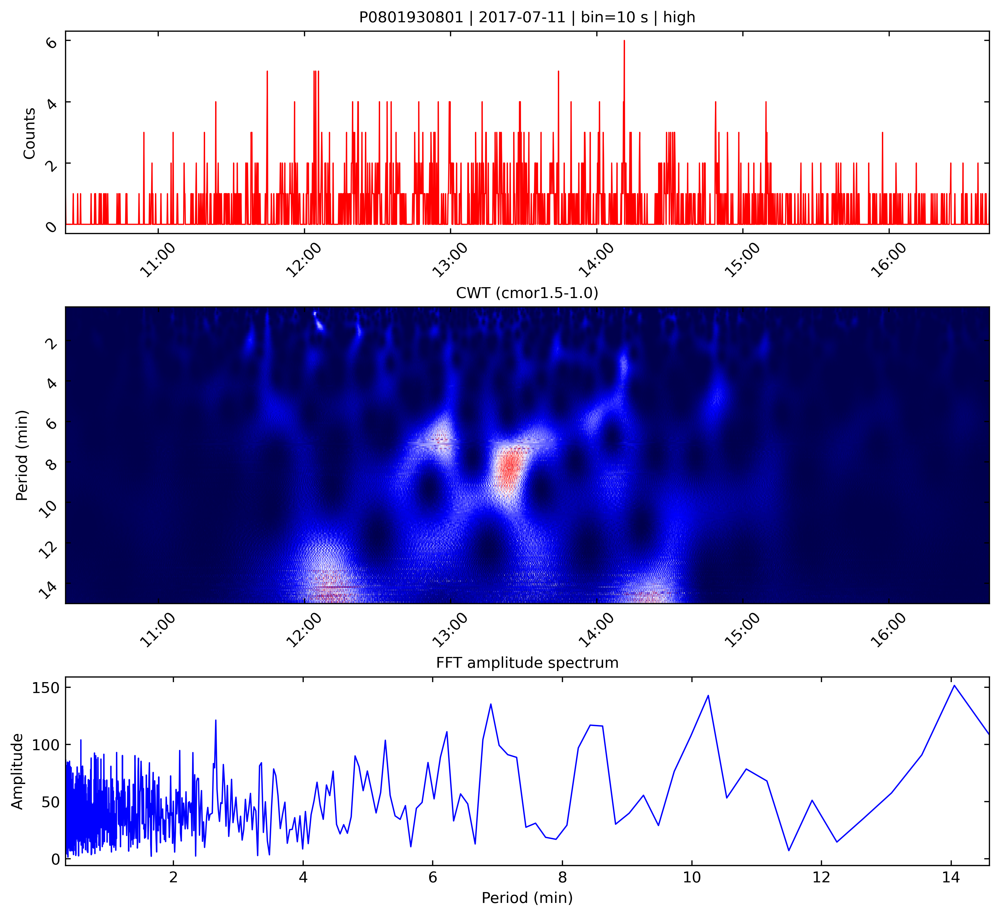

Finished P0801930801 | seg_bin=10 s | category=high


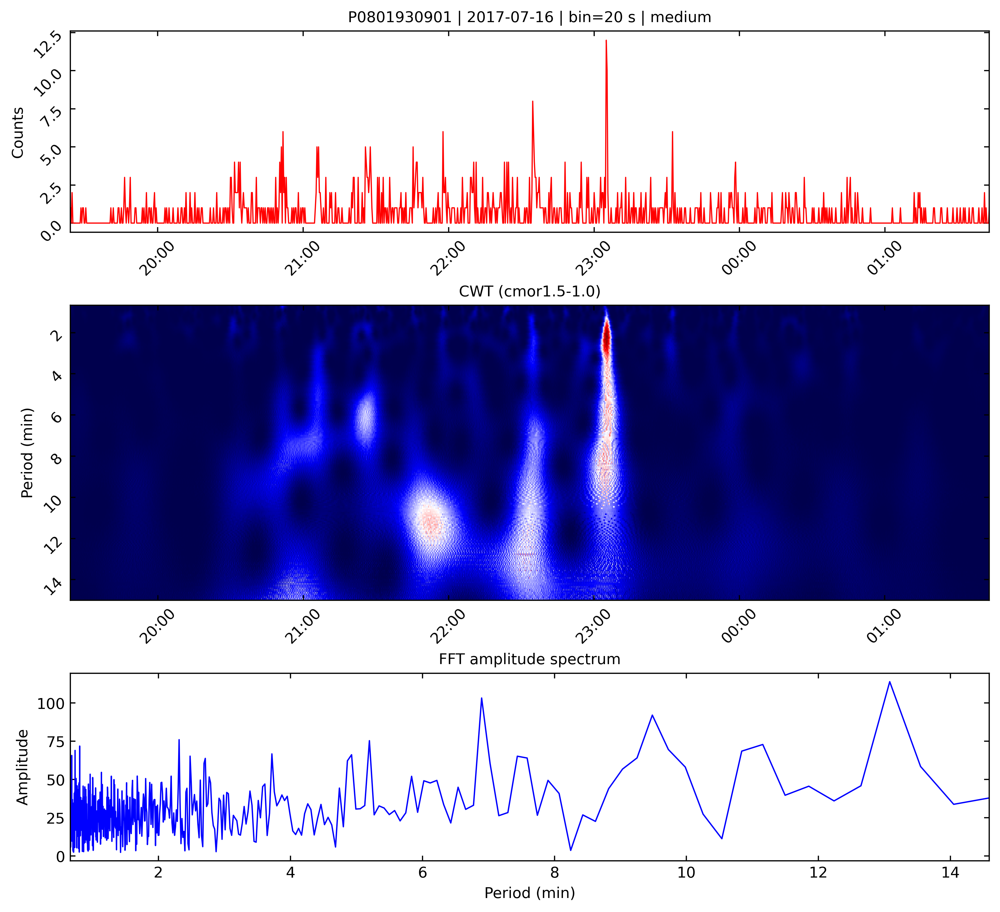

Finished P0801930901 | seg_bin=20 s | category=medium


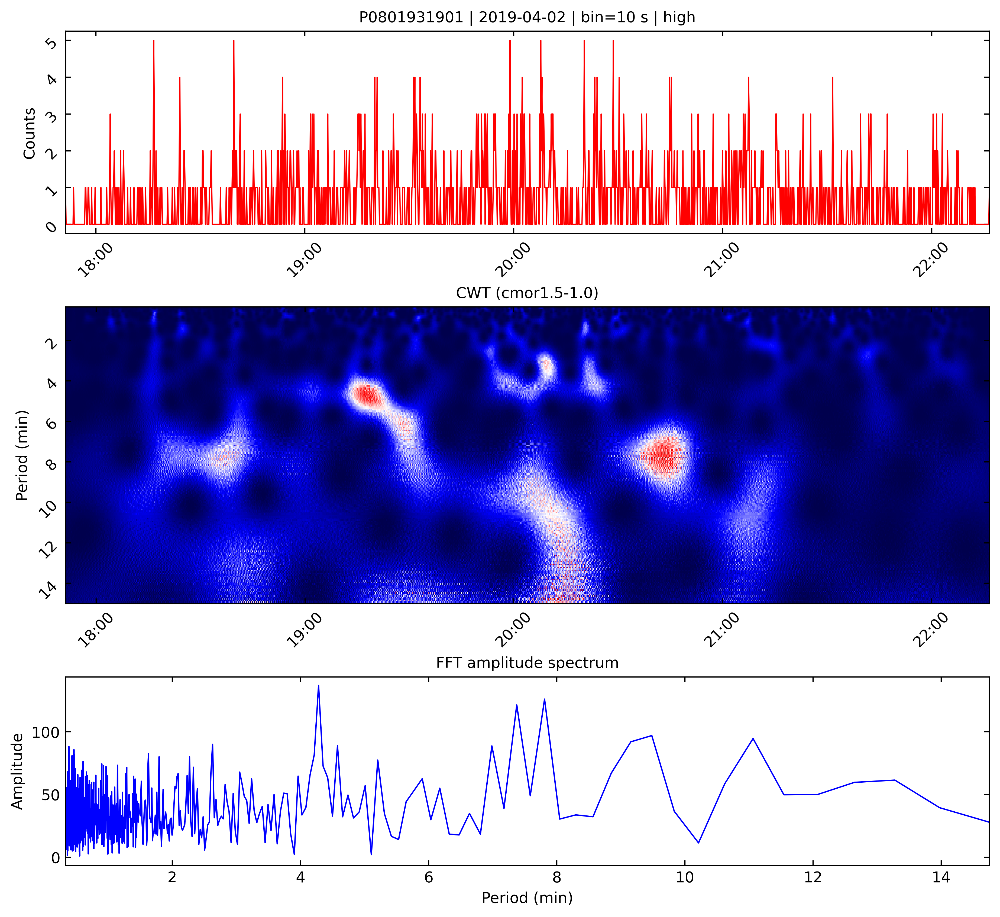

Finished P0801931901 | seg_bin=10 s | category=high


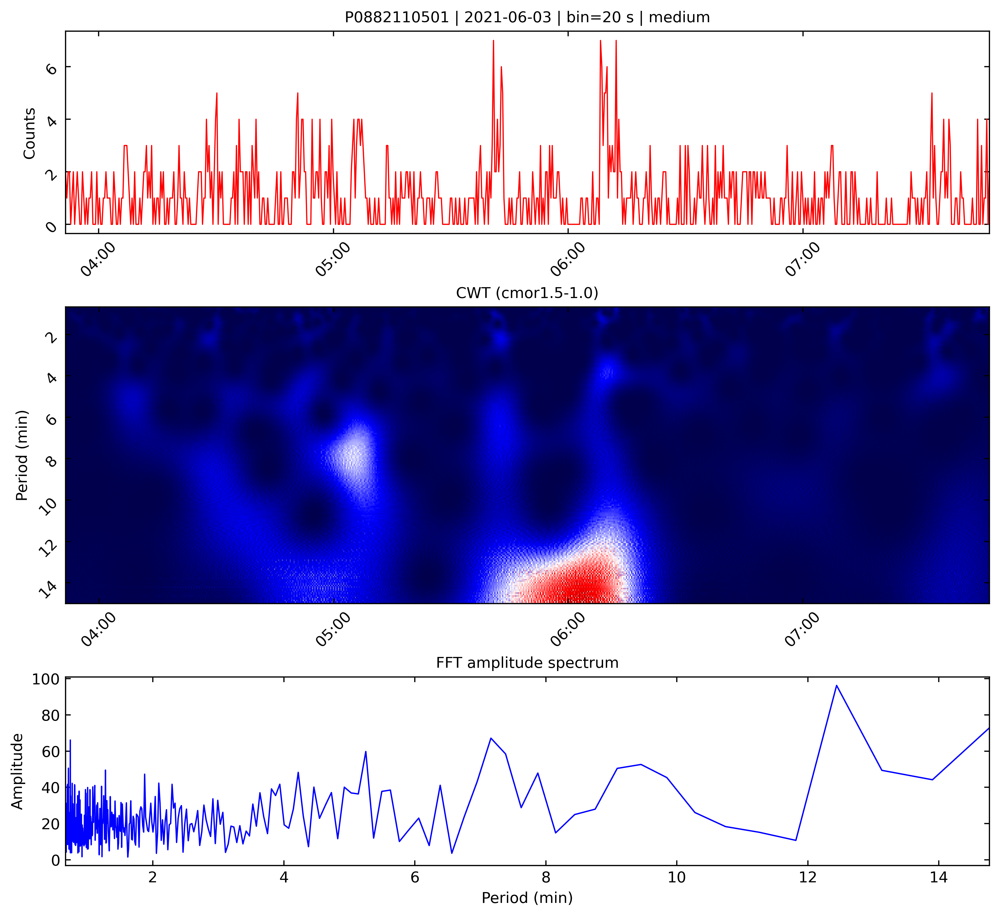

Finished P0882110501 | seg_bin=20 s | category=medium


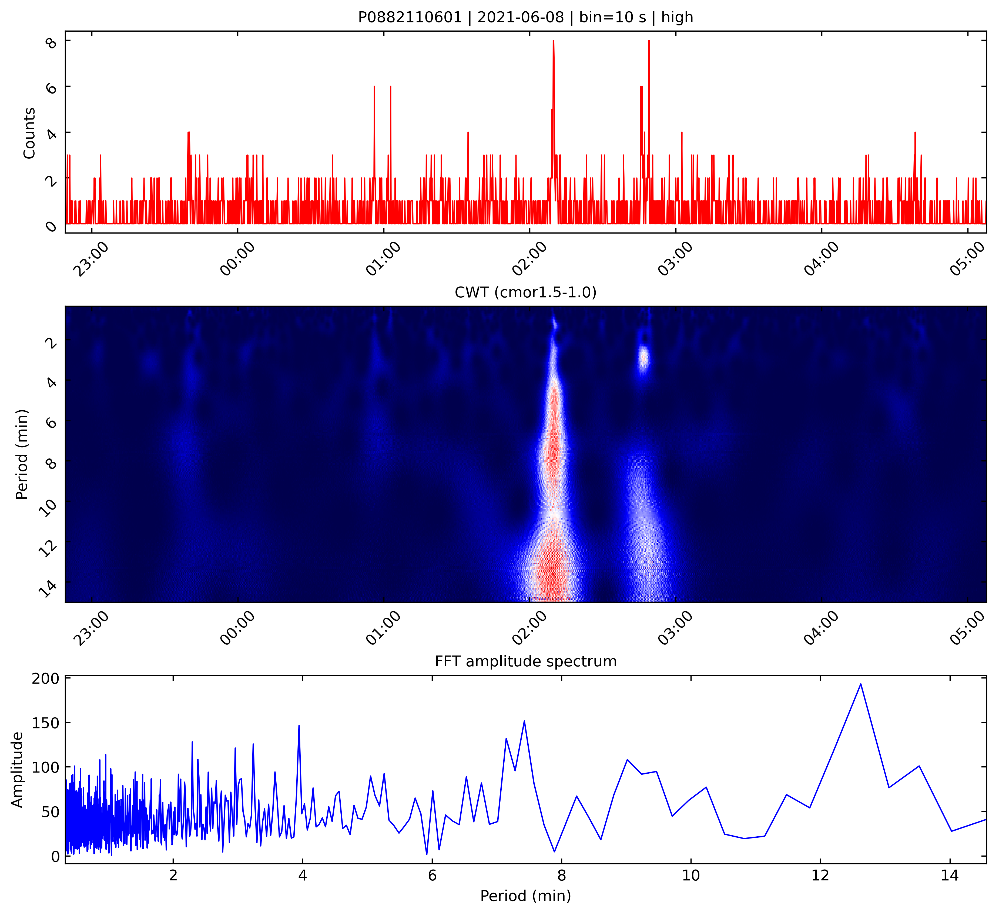

Finished P0882110601 | seg_bin=10 s | category=high


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

from typing import Optional, Dict
from astropy.table import Table
from astropy.time import Time
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator
import warnings
warnings.filterwarnings("ignore")


# ─── USER SETTINGS ────────────────────────────────────────────────────────────
tick_interval_h = 1

ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']
TARGET_SEGMENTS = {
    'P0801930801': 2,
    'P0801930901': 1,
    'P0801931901': 3,
    'P0882110501': 3,
    'P0882110601': 5
}

base_bin_size = 10
data_dir = 'Data_Files/Fenn_Data/'


# ─── IO + PREP ────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)  # approximate XMM as Earth-based

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    """
    Identify indices where the gap between consecutive times > threshold seconds.
    Returns:
      gaps    : list of (gap_start, gap_end) in cxcsec
      indices : ndarray of indices i such that times[i+1]-times[i] > threshold
    """
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


# ─── BINNING ──────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    """
    Bin photon_times (CXC seconds) into bins of width=bin_size seconds.
    Returns:
      centers_cxcsec, counts
    """
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    """
    1) initial bin with base_bin to categorise
    2) choose seg_bin via dynamic_bin_size
    3) re-bin with seg_bin
    """
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ─── PREPROCESSING ────────────────────────────────────────────────────────────
def preprocess_lightcurve(hist_counts: np.ndarray, detrend: bool = True, standardize: bool = True):
    """
    Simple preprocessing for FFT/CWT:
      - optional linear detrend
      - mean removal
      - optional standardization
    """
    y = hist_counts.astype(float).copy()
    x = np.arange(len(y), dtype=float)

    if detrend and len(y) >= 2:
        p = np.polyfit(x, y, 1)
        trend = np.polyval(p, x)
        y = y - trend

    y = y - np.nanmean(y)

    if standardize:
        std = np.nanstd(y)
        if std > 0:
            y = y / std

    return y


# ─── FFT ──────────────────────────────────────────────────────────────────────
def compute_lightcurve_fft(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
):
    """
    Compute a simple FFT amplitude spectrum on the binned lightcurve.

    Returns:
      periods_min, amplitudes
    """
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for FFT.")

    dt = float(seg_bin)  # seconds

    fft_vals = np.fft.rfft(y)
    freqs_hz = np.fft.rfftfreq(n, d=dt)

    # drop DC
    keep = freqs_hz > 0
    freqs_hz = freqs_hz[keep]
    fft_vals = fft_vals[keep]

    periods_min = (1.0 / freqs_hz) / 60.0
    amplitudes = np.abs(fft_vals)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    mask = (periods_min >= period_min_min) & (periods_min <= period_max_min)

    periods_min = periods_min[mask]
    amplitudes = amplitudes[mask]

    # sort by increasing period for plotting
    order = np.argsort(periods_min)
    return periods_min[order], amplitudes[order]


# ─── CWT (CMORL / COMPLEX MORLET) ────────────────────────────────────────────
def compute_lightcurve_cwt(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
    n_periods: int = 200,
    wavelet_name: str = 'cmor1.5-1.0',
):
    """
    Compute complex Morlet CWT on the binned lightcurve.

    Returns:
      periods_min         : sampled CWT periods
      power              : |coefficients|^2, shape (n_periods, n_times)
      times_min_from_start
      coeffs             : complex coefficients
    """
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for CWT.")

    dt = float(seg_bin)  # seconds
    sampling_period = dt

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    periods_min = np.linspace(period_min_min, period_max_min, n_periods)
    periods_s = periods_min * 60.0

    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = periods_s * central_freq / sampling_period

    coeffs, freqs_hz = pywt.cwt(y, scales, wavelet, sampling_period=sampling_period)
    power = np.abs(coeffs) ** 2
    times_min_from_start = np.arange(n) * dt / 60.0

    return periods_min, power, times_min_from_start, coeffs


# ─── PLOTTING ─────────────────────────────────────────────────────────────────
def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category,
                            obs_id, start_iso, end_iso):
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.8)

    title = f"{obs_id} | {start_iso[:10]} | bin={int(seg_bin)} s | {category}"
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Counts")
    ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)


def plot_cwt_subplot(ax, hist_centers, periods_min, power, obs_id, wavelet_name):
    hist_dt = Time(hist_centers, format='cxcsec').datetime

    t0 = hist_dt[0]
    x = hist_dt

    pcm = ax.pcolormesh(
        x,
        periods_min,
        power,
        shading='auto',
        cmap='seismic'
    )

    ax.set_ylabel("Period (min)")
    ax.set_title(f"CWT ({wavelet_name})", fontsize=10)
    ax.set_ylim(periods_min[0], periods_min[-1])
    ax.invert_yaxis()  # optional: short periods at top
    ax.xaxis.set_major_locator(HourLocator(interval=1))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)

    return pcm


def plot_fft_subplot(ax, periods_min, amplitudes):
    ax.plot(periods_min, amplitudes, lw=0.9, c='blue')
    ax.set_title("FFT amplitude spectrum", fontsize=10)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Amplitude")
    ax.tick_params(direction='in', top=True, right=True)

    if len(periods_min) > 0:
        ax.set_xlim(periods_min.min(), periods_min.max())


# ─── FINAL WRAPPER ────────────────────────────────────────────────────────────
def run_xmm_lc_segment_analysis_cwt_fft(
    obs_id: str,
    data_dir: str = "Data_Files/Fenn_Data/",
    base_bin_size: int = 10,
    gap_threshold_s: int = 3600,
    target_segments: Optional[Dict[str, int]] = None,
    save_path: Optional[str] = None,
    show: bool = True,
    dpi: int = 200,
    period_max_min: float = 15.0,
    period_min_min: Optional[float] = None,
    wavelet_name: str = 'cmor1.5-1.0',
    n_cwt_periods: int = 200,
):
    """
    End-to-end wrapper for:
      - load combined EPIC photon times
      - gap-split into segments
      - optional 1-based segment selection from target_segments
      - dynamic binning
      - lightcurve + cmor CWT + FFT

    Default lower-period limit is 2*seg_bin.
    """
    if target_segments is None:
        target_segments = {}

    # Load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading (N={times_cxc.size}).")

    order = np.argsort(times_cxc)
    t_sorted = times_cxc[order]

    # Gap split
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    segments = []
    seg_times_iso = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            segments.append(seg)
            seg_times_iso.append((
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))

    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    # Optional segment selection (1-based)
    selected_1based = target_segments.get(obs_id, None)
    if selected_1based is not None:
        k = selected_1based - 1
        if not (0 <= k < len(segments)):
            raise ValueError(
                f"{obs_id}: requested segment {selected_1based} "
                f"but only {len(segments)} segments exist."
            )
        segments = [segments[k]]
        seg_times_iso = [seg_times_iso[k]]

    seg = segments[0]
    start_iso, end_iso = seg_times_iso[0]

    # Binning
    seg_bin, hist_centers, hist_counts, category = prepare_segment_bins(seg, base_bin_size)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    # CWT
    cwt_periods_min, cwt_power, cwt_times_min, cwt_coeffs = compute_lightcurve_cwt(
        hist_counts=hist_counts,
        seg_bin=seg_bin,
        period_min_min=period_min_min,
        period_max_min=period_max_min,
        n_periods=n_cwt_periods,
        wavelet_name=wavelet_name,
    )

    # FFT
    fft_periods_min, fft_amplitudes = compute_lightcurve_fft(
        hist_counts=hist_counts,
        seg_bin=seg_bin,
        period_min_min=period_min_min,
        period_max_min=period_max_min,
    )

    # Plot
    fig, (ax_lc, ax_cwt, ax_fft) = plt.subplots(
        3, 1,
        figsize=(11, 10),
        dpi=dpi,
        gridspec_kw={"height_ratios": [1.5, 2.2, 1.4], "hspace": 0.32}
    )

    plot_lightcurve_subplot(
        ax_lc, hist_centers, hist_counts, seg_bin, category, obs_id, start_iso, end_iso
    )
    ax_lc.set_xlabel("")

    pcm = plot_cwt_subplot(
        ax_cwt, hist_centers, cwt_periods_min, cwt_power, obs_id, wavelet_name
    )
    ax_cwt.set_xlabel("")

    #cbar = fig.colorbar(pcm, ax=ax_cwt, pad=0.02)
    #cbar.set_label("CWT power")

    plot_fft_subplot(ax_fft, fft_periods_min, fft_amplitudes)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "obs_id": obs_id,
        "selected_segment_1based": selected_1based,
        "start_iso": start_iso,
        "end_iso": end_iso,
        "category": category,
        "seg_bin_s": seg_bin,
        "hist_centers_cxcsec": hist_centers,
        "hist_counts": hist_counts,
        "cwt_periods_min": cwt_periods_min,
        "cwt_power": cwt_power,
        "cwt_coeffs": cwt_coeffs,
        "fft_periods_min": fft_periods_min,
        "fft_amplitudes": fft_amplitudes,
        "n_segments_found": len(segments) if selected_1based is None else None,
    }


# ─── BATCH DRIVER ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    for obs_id in ident:
        out = run_xmm_lc_segment_analysis_cwt_fft(
            obs_id=obs_id,
            data_dir=data_dir,
            base_bin_size=base_bin_size,
            gap_threshold_s=3600,
            target_segments=TARGET_SEGMENTS,
            save_path=f"{obs_id}_lc_cwt_fft.png",
            show=True,
            dpi=400,
            period_max_min=15.0,
            period_min_min=None,          # defaults to 2*seg_bin
            wavelet_name='cmor1.5-1.0',   # complex Morlet
            n_cwt_periods=200,
        )
        print(
            f"Finished {obs_id} | seg_bin={out['seg_bin_s']} s | "
            f"category={out['category']}"
        )

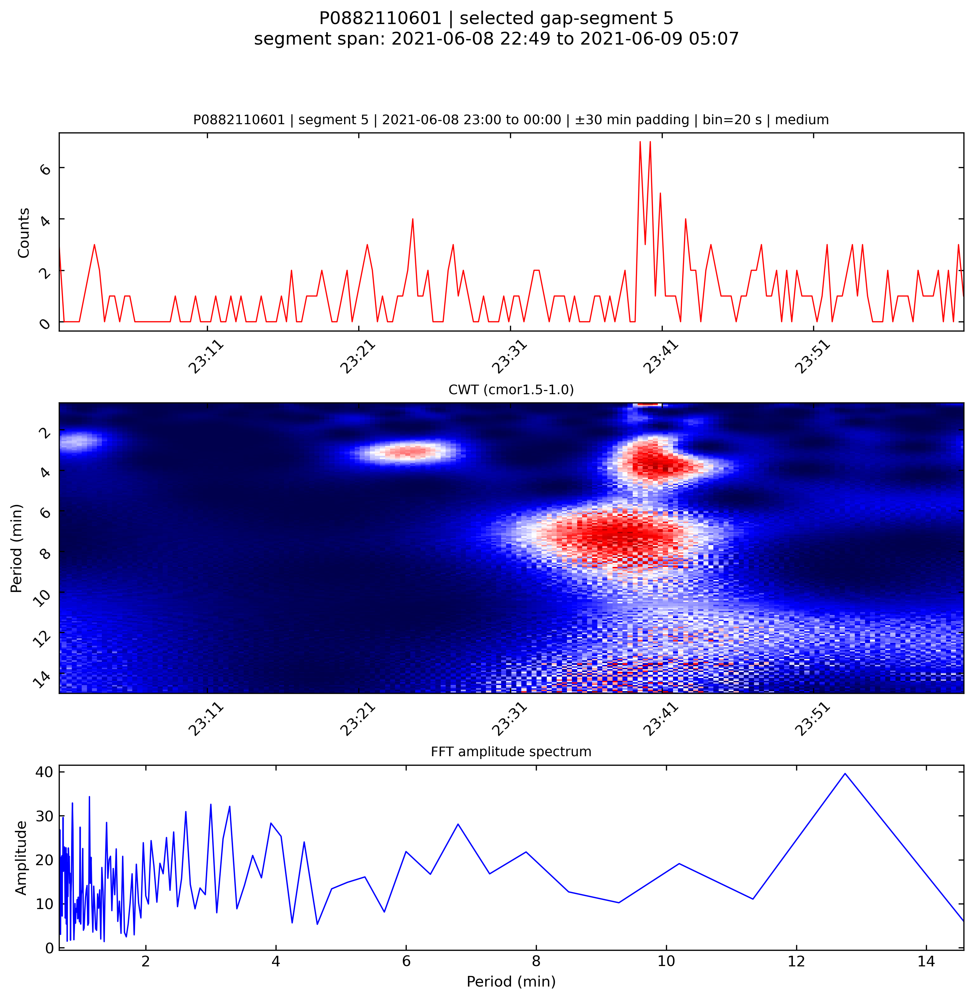

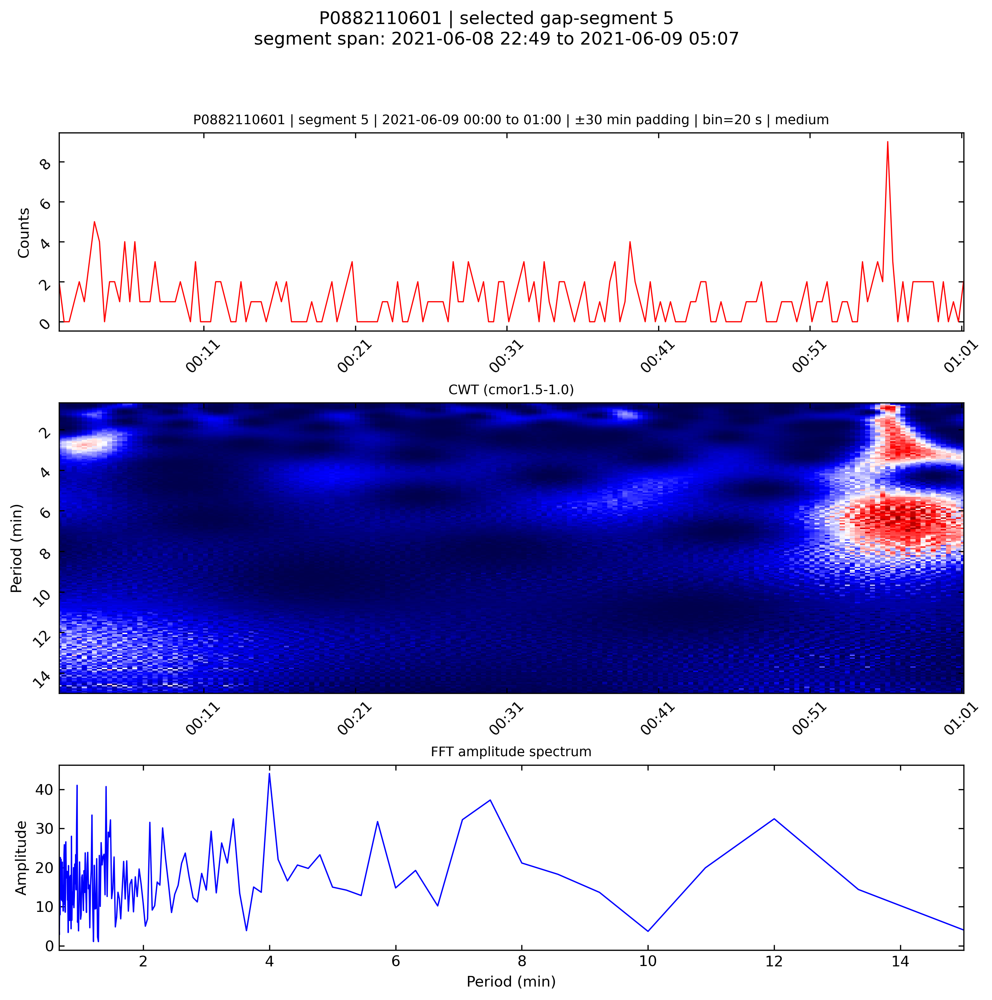

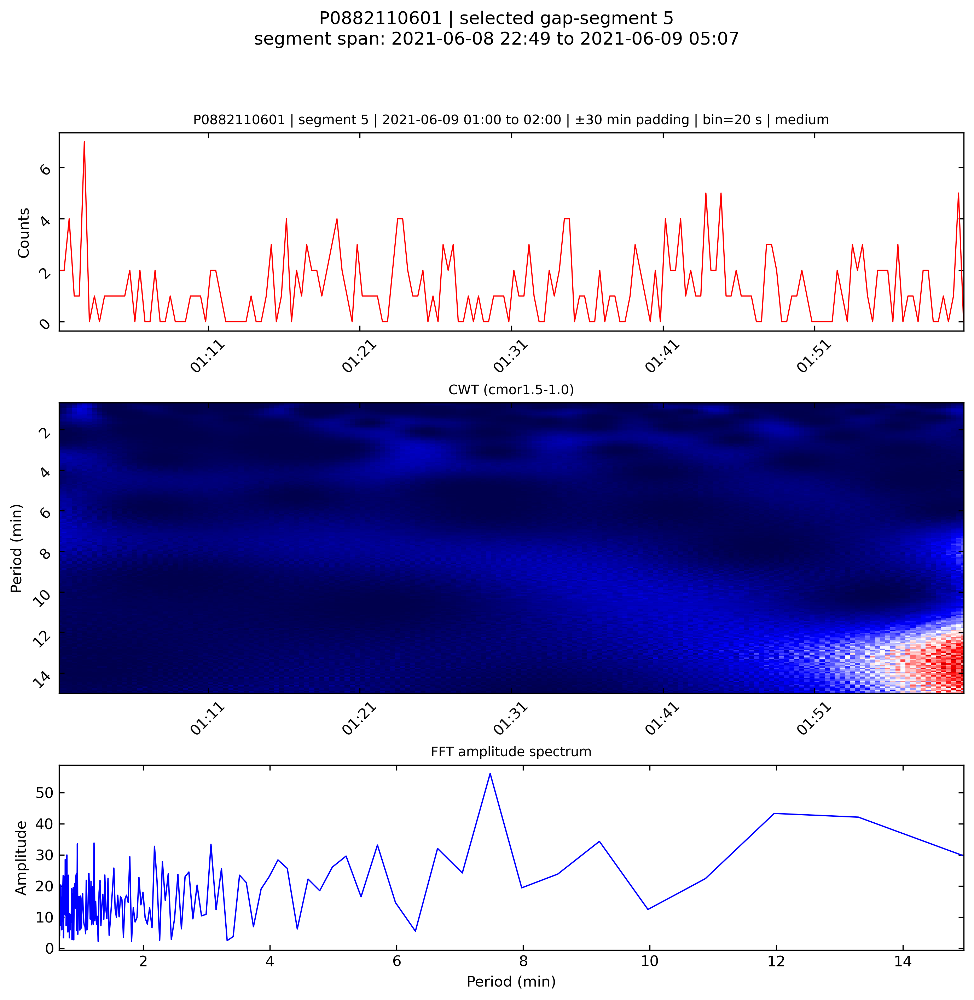

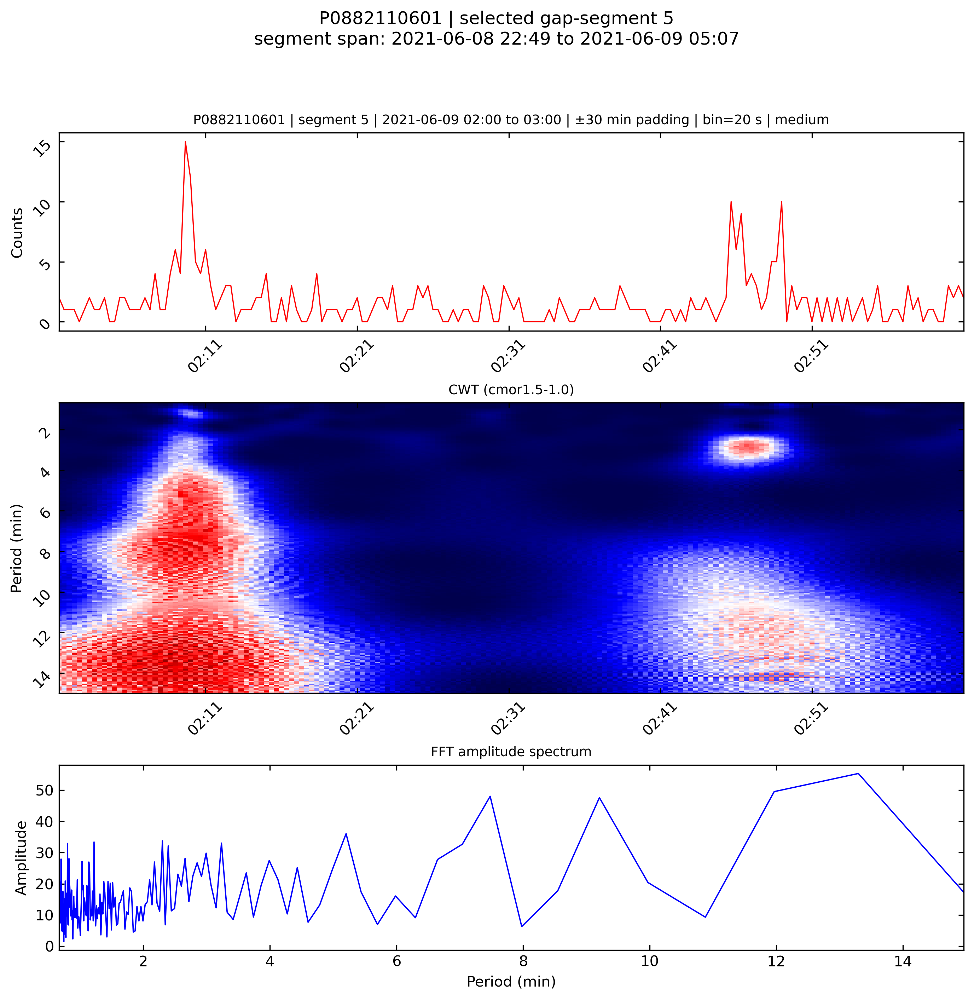

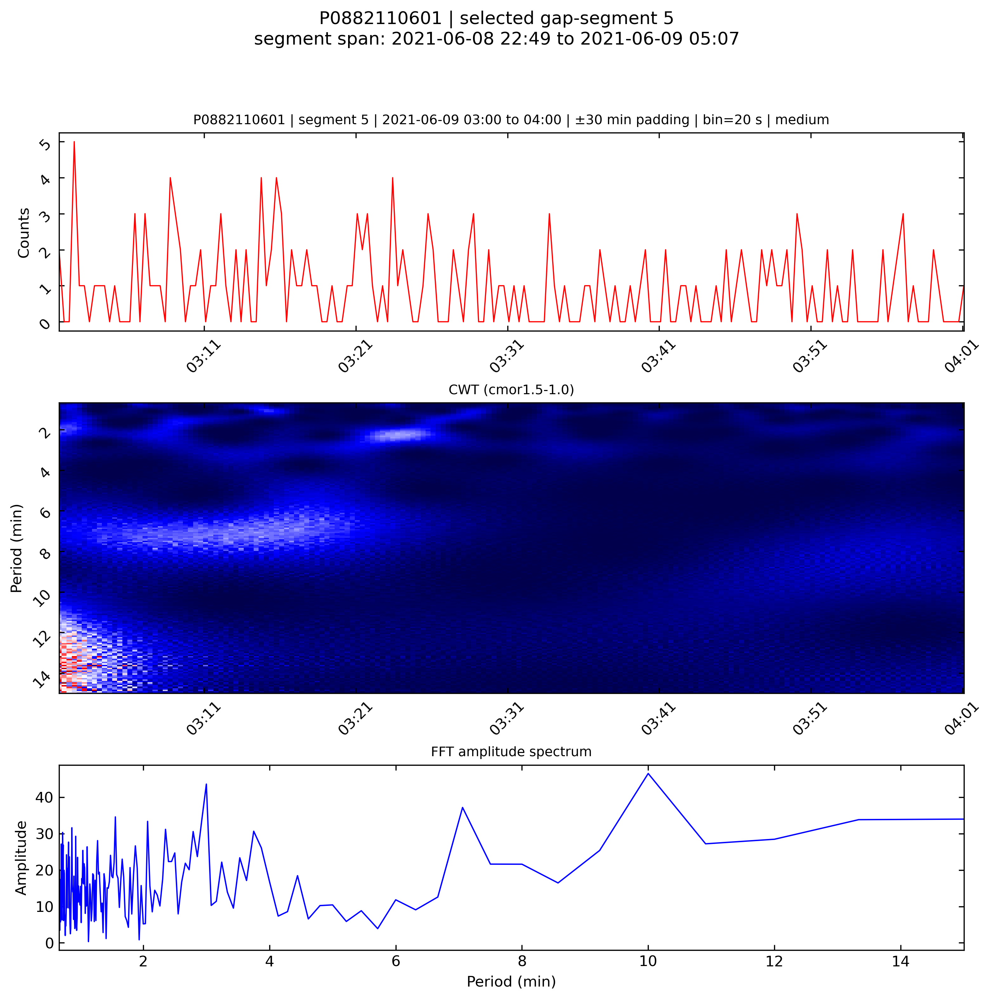

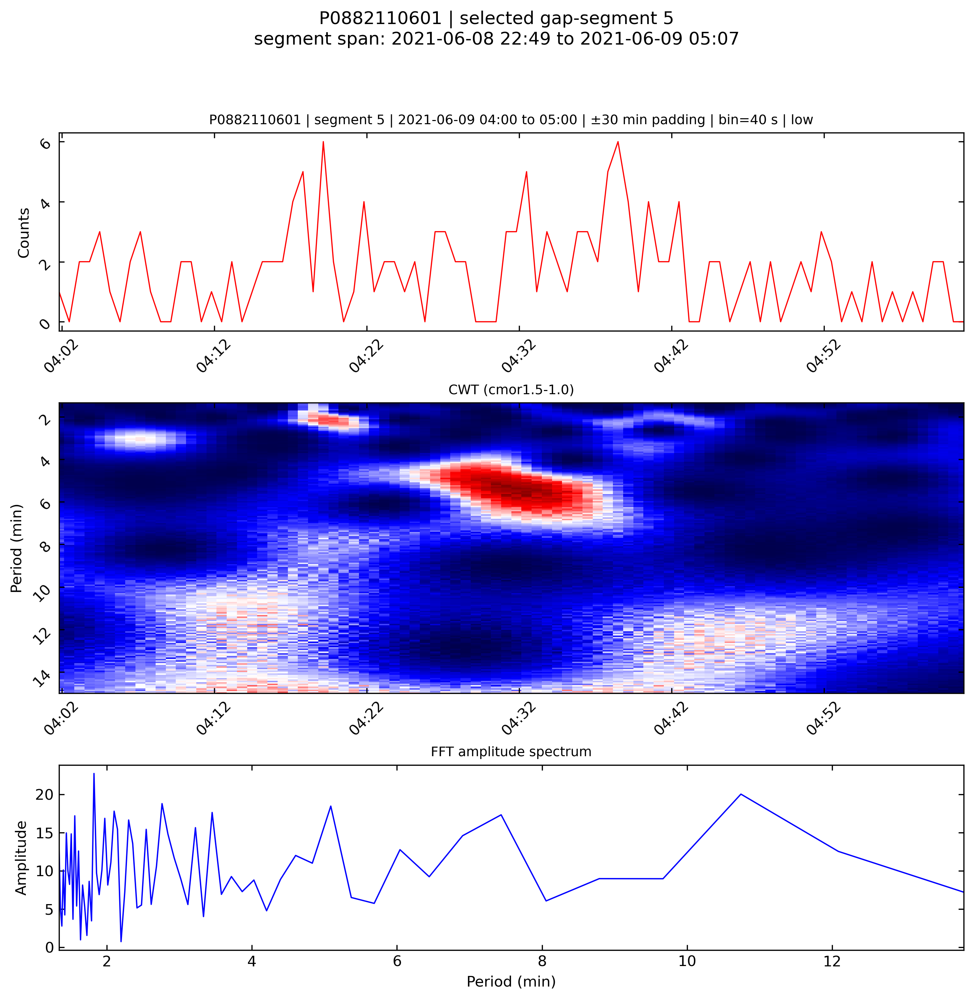

Produced 6 separate hourly figures.
2021-06-08 23:00 to 00:00
2021-06-09 00:00 to 01:00
2021-06-09 01:00 to 02:00
2021-06-09 02:00 to 03:00
2021-06-09 03:00 to 04:00
2021-06-09 04:00 to 05:00


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

from typing import Optional, List, Tuple
from datetime import timedelta

from astropy.table import Table
from astropy.time import Time
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from matplotlib.dates import DateFormatter, HourLocator, MinuteLocator
import warnings
warnings.filterwarnings("ignore")


# ──────────────────────────────────────────────────────────────────────────────
# USER SETTINGS
# ──────────────────────────────────────────────────────────────────────────────
data_dir = 'Data_Files/Fenn_Data/'
base_bin_size = 10
gap_threshold_s = 3600

# choose one observation and one gap-defined segment
OBS_ID = 'P0882110601'
SEGMENT_1BASED = 5

# hourly analysis settings
HOURLY_PAD_MINUTES = 30.0
PERIOD_MAX_MIN = 15.0
PERIOD_MIN_MIN = None          # if None -> defaults to 2 * seg_bin / 60
N_CWT_PERIODS = 200
WAVELET_NAME = 'cmor1.5-1.0'

SHOW_FIG = True
SAVE_FIG = False
OUTFILE = f"{OBS_ID}_segment{SEGMENT_1BASED}_hourly_lc_cwt_fft.png"
DPI = 300


# ──────────────────────────────────────────────────────────────────────────────
# IO + PREP
# ──────────────────────────────────────────────────────────────────────────────
def load_combined_times(obs_id: str, data_dir: str):
    """
    Read all three EPIC cameras, correct for Jupiter–Earth light travel time,
    and return:
      times_datetime : ndarray[datetime]
      times_cxcsec   : ndarray[float]
    """
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s
        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    return np.hstack(list_dt), np.hstack(list_cxc)


def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices


def build_gap_segments(
    t_sorted: np.ndarray,
    gap_threshold_s: float = 3600.0,
) -> List[Tuple[np.ndarray, str, str]]:
    """
    Returns:
      [(segment_times_cxc, start_iso, end_iso), ...]
    """
    _, gap_idx = find_gaps(t_sorted, threshold=float(gap_threshold_s))
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))

    out = []
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            out.append((
                seg,
                Time(seg[0], format='cxcsec').iso,
                Time(seg[-1], format='cxcsec').iso
            ))
    return out


# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────
def bin_photon_times(photon_times: np.ndarray, bin_size: float):
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh:
        return 'low'
    elif total < high_thresh:
        return 'medium'
    return 'high'


def dynamic_bin_size(category: str, base_bin: int = 120):
    if category == 'low':
        return base_bin * 4
    elif category == 'medium':
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    hist_centers, hist_counts = bin_photon_times(raw_segment, seg_bin)
    return seg_bin, hist_centers, hist_counts, category


# ──────────────────────────────────────────────────────────────────────────────
# PREPROCESSING
# ──────────────────────────────────────────────────────────────────────────────
def preprocess_lightcurve(hist_counts: np.ndarray, detrend: bool = True, standardize: bool = True):
    y = hist_counts.astype(float).copy()
    x = np.arange(len(y), dtype=float)

    if detrend and len(y) >= 2:
        p = np.polyfit(x, y, 1)
        trend = np.polyval(p, x)
        y = y - trend

    y = y - np.nanmean(y)

    if standardize:
        std = np.nanstd(y)
        if std > 0:
            y = y / std

    return y


# ──────────────────────────────────────────────────────────────────────────────
# FFT
# ──────────────────────────────────────────────────────────────────────────────
def compute_lightcurve_fft(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
):
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for FFT.")

    dt = float(seg_bin)
    fft_vals = np.fft.rfft(y)
    freqs_hz = np.fft.rfftfreq(n, d=dt)

    keep = freqs_hz > 0
    freqs_hz = freqs_hz[keep]
    fft_vals = fft_vals[keep]

    periods_min = (1.0 / freqs_hz) / 60.0
    amplitudes = np.abs(fft_vals)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    mask = (periods_min >= period_min_min) & (periods_min <= period_max_min)
    periods_min = periods_min[mask]
    amplitudes = amplitudes[mask]

    order = np.argsort(periods_min)
    return periods_min[order], amplitudes[order]


# ──────────────────────────────────────────────────────────────────────────────
# CWT
# ──────────────────────────────────────────────────────────────────────────────
def compute_lightcurve_cwt(
    hist_counts: np.ndarray,
    seg_bin: float,
    period_min_min: Optional[float] = None,
    period_max_min: float = 15.0,
    n_periods: int = 200,
    wavelet_name: str = 'cmor1.5-1.0',
):
    y = preprocess_lightcurve(hist_counts, detrend=True, standardize=True)
    n = len(y)

    if n < 4:
        raise ValueError("Not enough bins for CWT.")

    dt = float(seg_bin)

    if period_min_min is None:
        period_min_min = 2.0 * seg_bin / 60.0

    periods_min = np.linspace(period_min_min, period_max_min, n_periods)
    periods_s = periods_min * 60.0

    wavelet = pywt.ContinuousWavelet(wavelet_name)
    central_freq = pywt.central_frequency(wavelet)
    scales = periods_s * central_freq / dt

    coeffs, _ = pywt.cwt(y, scales, wavelet, sampling_period=dt)
    power = np.abs(coeffs) ** 2

    return periods_min, power, coeffs


# ──────────────────────────────────────────────────────────────────────────────
# HOURLY WINDOWS WITHIN A SELECTED SEGMENT
# ──────────────────────────────────────────────────────────────────────────────
def build_hourly_windows_in_segment(
    seg_times_cxc: np.ndarray,
    min_events_in_core: int = 5,
):
    """
    Build full-hour windows entirely inside the selected gap-segment.
    Example:
      01:00-02:00, 02:00-03:00, etc.
    """
    if seg_times_cxc.size == 0:
        return []

    seg_start_dt = Time(seg_times_cxc[0], format='cxcsec').datetime
    seg_end_dt = Time(seg_times_cxc[-1], format='cxcsec').datetime

    first_hour = seg_start_dt.replace(minute=0, second=0, microsecond=0)
    if first_hour < seg_start_dt:
        first_hour = first_hour + timedelta(hours=1)

    windows = []
    current = first_hour

    while current + timedelta(hours=1) <= seg_end_dt:
        nxt = current + timedelta(hours=1)

        current_cxc = Time(current).cxcsec
        nxt_cxc = Time(nxt).cxcsec

        mask_core = (seg_times_cxc >= current_cxc) & (seg_times_cxc < nxt_cxc)
        core_times = seg_times_cxc[mask_core]

        if core_times.size >= min_events_in_core:
            windows.append({
                "core_start_dt": current,
                "core_end_dt": nxt,
                "core_start_cxc": current_cxc,
                "core_end_cxc": nxt_cxc,
                "core_times": core_times,
            })

        current = nxt

    return windows


def build_padded_hour_from_segment(
    seg_times_cxc: np.ndarray,
    core_start_cxc: float,
    core_end_cxc: float,
    pad_minutes: float = 30.0,
):
    """
    Padding is limited to the available data inside the selected segment.
    """
    pad_s = pad_minutes * 60.0
    pad_start = max(float(seg_times_cxc[0]), core_start_cxc - pad_s)
    pad_end = min(float(seg_times_cxc[-1]), core_end_cxc + pad_s)

    mask_pad = (seg_times_cxc >= pad_start) & (seg_times_cxc <= pad_end)
    pad_times = seg_times_cxc[mask_pad]

    return {
        "pad_start_cxc": pad_start,
        "pad_end_cxc": pad_end,
        "pad_times": pad_times,
    }


def crop_binned_to_core(hist_centers, hist_counts, core_start_cxc, core_end_cxc):
    mask = (hist_centers >= core_start_cxc) & (hist_centers < core_end_cxc)
    return hist_centers[mask], hist_counts[mask], mask


def crop_cwt_to_core(hist_centers, power, coeffs, core_start_cxc, core_end_cxc):
    mask = (hist_centers >= core_start_cxc) & (hist_centers < core_end_cxc)
    return hist_centers[mask], power[:, mask], coeffs[:, mask], mask


# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────
def plot_lightcurve_subplot(ax, hist_centers, hist_counts, seg_bin, category, title_text):
    hist_dt = Time(hist_centers, format='cxcsec').datetime
    ax.plot(hist_dt, hist_counts, c='red', lw=0.8)

    ax.set_title(f"{title_text} | bin={int(seg_bin)} s | {category}", fontsize=9)
    ax.set_ylabel("Counts")

    if len(hist_dt) > 0:
        ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(MinuteLocator(interval=10))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)


def plot_cwt_subplot(ax, hist_centers, periods_min, power, wavelet_name):
    hist_dt = Time(hist_centers, format='cxcsec').datetime

    pcm = ax.pcolormesh(
        hist_dt,
        periods_min,
        power,
        shading='auto',
        cmap='seismic'
    )

    ax.set_ylabel("Period (min)")
    ax.set_title(f"CWT ({wavelet_name})", fontsize=9)
    ax.set_ylim(periods_min[0], periods_min[-1])
    ax.invert_yaxis()

    if len(hist_dt) > 0:
        ax.set_xlim(hist_dt[0], hist_dt[-1])

    ax.xaxis.set_major_locator(MinuteLocator(interval=10))
    ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))
    ax.tick_params(rotation=45, direction='in', top=True, right=True)

    return pcm


def plot_fft_subplot(ax, periods_min, amplitudes):
    ax.plot(periods_min, amplitudes, lw=0.9, c='blue')
    ax.set_title("FFT amplitude spectrum", fontsize=9)
    ax.set_xlabel("Period (min)")
    ax.set_ylabel("Amplitude")
    ax.tick_params(direction='in', top=True, right=True)

    if len(periods_min) > 0:
        ax.set_xlim(periods_min.min(), periods_min.max())


# ──────────────────────────────────────────────────────────────────────────────
# MAIN DRIVER
# ──────────────────────────────────────────────────────────────────────────────
def run_selected_segment_hourly_panels(
    obs_id: str,
    segment_1based: int,
    data_dir: str = 'Data_Files/Fenn_Data/',
    base_bin_size: int = 10,
    gap_threshold_s: float = 3600,
    hourly_pad_minutes: float = 30.0,
    period_max_min: float = 15.0,
    period_min_min: Optional[float] = None,
    n_cwt_periods: int = 200,
    wavelet_name: str = 'cmor1.5-1.0',
    min_events_in_core_hour: int = 5,
    show: bool = True,
    save_dir: Optional[str] = None,
    save_prefix: Optional[str] = None,
    dpi: int = 300,
):
    """
    For one selected gap-defined segment, produce ONE FIGURE PER FULL HOUR
    inside that segment.

    Returns
    -------
    results : list of dict
        One entry per produced hour-figure.
    """
    import os

    # load + sort
    _, times_cxc = load_combined_times(obs_id, data_dir)
    if times_cxc.size < 10:
        raise ValueError(f"{obs_id}: not enough events after loading.")

    t_sorted = np.sort(times_cxc)

    # split by gaps and select segment
    segments = build_gap_segments(t_sorted, gap_threshold_s=gap_threshold_s)
    if len(segments) == 0:
        raise ValueError(f"{obs_id}: no valid segments after gap-splitting.")

    k = segment_1based - 1
    if not (0 <= k < len(segments)):
        raise ValueError(
            f"{obs_id}: requested segment {segment_1based}, "
            f"but only {len(segments)} segments exist."
        )

    seg_times_cxc, seg_start_iso, seg_end_iso = segments[k]

    # build full-hour windows within selected segment
    hour_windows = build_hourly_windows_in_segment(
        seg_times_cxc,
        min_events_in_core=min_events_in_core_hour,
    )
    if len(hour_windows) == 0:
        raise ValueError(
            f"{obs_id} segment {segment_1based}: no full-hour windows found inside the segment."
        )

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

    results = []

    for i, w in enumerate(hour_windows):
        core_start_dt = w["core_start_dt"]
        core_end_dt = w["core_end_dt"]
        core_start_cxc = w["core_start_cxc"]
        core_end_cxc = w["core_end_cxc"]

        padded = build_padded_hour_from_segment(
            seg_times_cxc,
            core_start_cxc=core_start_cxc,
            core_end_cxc=core_end_cxc,
            pad_minutes=hourly_pad_minutes,
        )
        pad_times = padded["pad_times"]

        if pad_times.size < 5:
            continue

        seg_bin, hist_centers_pad, hist_counts_pad, category = prepare_segment_bins(
            pad_times, base_bin_size
        )

        use_period_min = period_min_min
        if use_period_min is None:
            use_period_min = 2.0 * seg_bin / 60.0

        # padded analysis
        cwt_periods_min, cwt_power_pad, cwt_coeffs_pad = compute_lightcurve_cwt(
            hist_counts=hist_counts_pad,
            seg_bin=seg_bin,
            period_min_min=use_period_min,
            period_max_min=period_max_min,
            n_periods=n_cwt_periods,
            wavelet_name=wavelet_name,
        )

        fft_periods_min, fft_amplitudes = compute_lightcurve_fft(
            hist_counts=hist_counts_pad,
            seg_bin=seg_bin,
            period_min_min=use_period_min,
            period_max_min=period_max_min,
        )

        # crop displayed LC/CWT to core hour
        lc_centers_core, lc_counts_core, _ = crop_binned_to_core(
            hist_centers_pad, hist_counts_pad, core_start_cxc, core_end_cxc
        )
        cwt_centers_core, cwt_power_core, cwt_coeffs_core, _ = crop_cwt_to_core(
            hist_centers_pad, cwt_power_pad, cwt_coeffs_pad, core_start_cxc, core_end_cxc
        )

        if len(lc_centers_core) == 0:
            continue

        # --- one figure per hour ---
        fig, (ax_lc, ax_cwt, ax_fft) = plt.subplots(
            3, 1,
            figsize=(11, 10),
            dpi=dpi,
            gridspec_kw={"height_ratios": [1.5, 2.2, 1.4], "hspace": 0.32}
        )

        hour_label = f"{core_start_dt.strftime('%Y-%m-%d %H:%M')} to {core_end_dt.strftime('%H:%M')}"
        title_text = (
            f"{obs_id} | segment {segment_1based} | {hour_label} "
            f"| ±{hourly_pad_minutes:.0f} min padding"
        )

        plot_lightcurve_subplot(
            ax_lc,
            lc_centers_core,
            lc_counts_core,
            seg_bin,
            category,
            title_text,
        )
        ax_lc.set_xlabel("")

        pcm = plot_cwt_subplot(
            ax_cwt,
            cwt_centers_core,
            cwt_periods_min,
            cwt_power_core,
            wavelet_name,
        )
        ax_cwt.set_xlabel("")
        #cbar = fig.colorbar(pcm, ax=ax_cwt, pad=0.02)
        #cbar.set_label("CWT power")

        plot_fft_subplot(ax_fft, fft_periods_min, fft_amplitudes)

        fig.suptitle(
            f"{obs_id} | selected gap-segment {segment_1based}\n"
            f"segment span: {seg_start_iso[:16]} to {seg_end_iso[:16]}",
            fontsize=12,
            y=0.995
        )

        plt.tight_layout(rect=[0, 0, 1, 0.985])

        saved_path = None
        if save_dir is not None:
            if save_prefix is None:
                save_prefix = f"{obs_id}_seg{segment_1based}"

            hour_tag = core_start_dt.strftime("%Y%m%d_%H%M")
            saved_path = os.path.join(save_dir, f"{save_prefix}_{hour_tag}.png")
            fig.savefig(saved_path, bbox_inches='tight')

        if show:
            plt.show()
        else:
            plt.close(fig)

        results.append({
            "hour_index_1based": i + 1,
            "hour_label": hour_label,
            "seg_bin_s": seg_bin,
            "category": category,
            "lc_centers_core": lc_centers_core,
            "lc_counts_core": lc_counts_core,
            "cwt_periods_min": cwt_periods_min,
            "cwt_power_core": cwt_power_core,
            "fft_periods_min": fft_periods_min,
            "fft_amplitudes": fft_amplitudes,
            "saved_path": saved_path,
        })

    return results


# ──────────────────────────────────────────────────────────────────────────────
# RUN
# ──────────────────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    results = run_selected_segment_hourly_panels(
        obs_id='P0882110601',
        segment_1based=5,
        data_dir=data_dir,
        base_bin_size=10,
        gap_threshold_s=3600,
        hourly_pad_minutes=30.0,
        period_max_min=15.0,
        period_min_min=None,
        n_cwt_periods=200,
        wavelet_name='cmor1.5-1.0',
        show=True,                 # show each figure separately
        save_dir='WAVES_FIGS/LC plots',             # or e.g. "hourly_figs"
        save_prefix="P0882110601_seg5",
        dpi=300,
    )

    print(f"Produced {len(results)} separate hourly figures.")
    for r in results:
        print(r["hour_label"])